Terrain EDA: shared centers, scale and spatial form

Follow-up to notebook 15 and [outline.md](../../outline.md).
Separate the change in window extent from changing eligible locations.
Then inspect how much spatial form can differ at similar slope and relief.
All results are exploratory. No fitted population normalization, retrieval
model, evaluation split or mission threshold is introduced here.

In [2]:
import hashlib
import json
import sys
from datetime import UTC, datetime
from importlib.metadata import version
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
import rasterio
from IPython.display import Image, Markdown, display
from matplotlib.figure import Figure

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'outline.md').exists())
sys.path.insert(0, str(ROOT))
from notebooks.shared.inspection import check_input, file_hash, verify_run
from notebooks.shared.patch_analysis import measure_patch, measure_planarity

NOTEBOOK = ROOT / 'notebooks/exploration/16_scale_and_spatial_form_eda.ipynb'
PREVIOUS = ROOT / 'data/processed/analysis/patch-eda-20261028T175445572789Z'
RUN_IDS = {'earth_terrain_landcover': '20261028T063142045472Z_9d6d3b',
           'lunar_terrain_views': '20261028T084443441751Z_1a794f'}
SIZES = [300, 600, 960]
CHANNELS = ['elevation_m', 'relative_elevation_m', 'slope_deg',
            'laplacian_per_m', 'local_elevation_std_m']
FEATURES = ['slope_median_deg', 'slope_p90_deg', 'central_relief_m', 'relief_m',
            'local_sd_median_m', 'plane_residual_rms_m', 'plane_residual_fraction']
GROUP = ['body', 'region', 'population']
PAIR_POLICIES = {'base': (1., 2., 5., .10), 'half': (.5, 1., 2.5, .05)}
OUT = ROOT / 'data/processed/analysis' / ('scale-eda-' + datetime.now(UTC).strftime('%Y%m%dT%H%M%S%fZ'))
OUT.mkdir(parents=True, exist_ok=False)
runs = {stage: ROOT / 'data/processed' / stage / run for stage, run in RUN_IDS.items()}
expected: dict[str, str] = {}
evidence: dict[str, str] = {}
for run in runs.values():
    expected.update(verify_run(run))
    evidence[str(run / 'provenance.json')] = file_hash(run / 'provenance.json')
previous_manifest = json.loads((PREVIOUS / 'provenance.json').read_text(encoding='utf-8'))
assert previous_manifest['status'] == 'complete'
expected.update({str((PREVIOUS / name).resolve()): digest for name, digest in previous_manifest['outputs'].items()})
evidence[str(PREVIOUS / 'provenance.json')] = file_hash(PREVIOUS / 'provenance.json')
old_stats = pd.read_csv(check_input(PREVIOUS / 'descriptor_statistics.csv', expected, evidence))
old_inventory = pd.read_csv(check_input(PREVIOUS / 'inventory.csv', expected, evidence))
source = '\n'.join(cell.source for cell in nbformat.read(NOTEBOOK, as_version=4).cells)
provenance: dict[str, Any] = {
    'status': 'running', 'notebook': str(NOTEBOOK.relative_to(ROOT)),
    'notebook_source_sha256': hashlib.sha256(source.encode()).hexdigest(),
    'helpers': {name: file_hash(ROOT / 'notebooks' / name) for name in ['shared/inspection.py', 'shared/patch_analysis.py']},
    'runs': RUN_IDS, 'previous_eda': str(PREVIOUS.relative_to(ROOT)),
    'sizes_m': SIZES, 'spacing_m': 30, 'center_origin_row_col': [16, 16],
    'center_stride_cells': 32, 'center_domain': '960 m window fits inside array; omit edge remainders',
    'eligibility': 'same five-channel policy as notebook 15; common requires complete 960 m',
    'pair_size_m': 600, 'pair_population': 'common 960 m centers, same site and view',
    'pair_policies': PAIR_POLICIES,
    'pair_policy_units': ['median slope degrees', 'P90 slope degrees', 'central relief floor m', 'relative central relief'],
    'pair_selection': 'largest absolute plane-residual-fraction contrast; ties by sorted row/col IDs',
    'findings_led_relief_floors_m': [10, 20, 40],
    'followup_gallery': 'half tolerance; central relief >=20 m for both; strict lunar view',
    'plane_fraction': 'RMS after per-patch least-squares plane / population elevation SD; constant=0',
    'quantile_method': 'linear', 'python': sys.version,
    'software': {name: version(name) for name in ['numpy', 'pandas', 'rasterio', 'matplotlib', 'nbformat']},
}
(OUT / 'provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .2})


def read_layer(path: Path) -> tuple[np.ndarray, tuple[Any, ...]]:
    with rasterio.open(check_input(path, expected, evidence)) as dataset:
        transform = dataset.transform
        assert dataset.count == 1 and dataset.scales == (1.,) and dataset.offsets == (0.,)
        assert transform.a == 30 and transform.e == -30 and transform.b == transform.d == 0
        assert dataset.crs is not None
        values = dataset.read(1, masked=True).astype('float32').filled(np.nan)
        assert not np.isinf(values).any()
        return values, (dataset.shape, transform, dataset.crs)


def save_figure(fig: Figure, name: str) -> None:
    fig.savefig(OUT / f'{name}.png', bbox_inches='tight')
    fig.savefig(OUT / f'{name}.pdf', bbox_inches='tight')
    display(Image(filename=str(OUT / f'{name}.png')))
    plt.close(fig)


print('Pinned inputs:', RUN_IDS)
print('Output:', OUT)

Pinned inputs: {'earth_terrain_landcover': '20261028T063142045472Z_9d6d3b', 'lunar_terrain_views': '20261028T084443441751Z_1a794f'}
Output: .\data\processed\analysis\scale-eda-20261102T143558484274Z


# Nested windows on one center lattice

A center is a grid intersection at row/column 16 + 32k (960 m stride).
Even-sided windows share that exact physical center: sides 10, 20 and 32 cells.
The center domain contains only locations where the 960 m square fits in the
array. At each size, retain every complete eligible window on this lattice.
The common cohort additionally requires the 960 m window to be eligible.

This controls centers in the paired comparison. It does not make the common
cohort representative of excluded areas. Notebook 15's denser, differently
aligned lattices are a reference; their difference also includes placement.
Local elevation SD still uses 330 m support, which extends beyond 300 m patches.
Plane residual RMS (m) removes a best-fitting tilt, and its fraction divides by
patch elevation SD. The fraction describes departure from a plane, not a
landform label or mobility difficulty. Near-flat patches need absolute RMS too.

In [3]:
site_specs = [('earth', p.parent.name, p) for p in
              sorted((runs['earth_terrain_landcover'] / 'earth').glob('*/grid_30m'))]
site_specs += [('moon', p.name, p) for p in sorted((runs['lunar_terrain_views'] / 'moon').iterdir())]
assert len(site_specs) == 10
records: list[dict[str, Any]] = []
counts: list[dict[str, Any]] = []
grids: dict[str, Any] = {}
layer_folders: dict[tuple[str, str], Path] = {}
strict_paths: dict[str, Path] = {}

for body, region, folder in site_specs:
    if body == 'earth':
        screen, grid = read_layer(folder / 'natural_screen_mask.tif')
        base = screen == 1
        views = [('natural_screen', folder)]
    else:
        coverage, grid = read_layer(folder / 'quality/source_coverage_fraction.tif')
        base = np.isfinite(coverage) & (coverage > 0)
        views = [(p, folder / p) for p in ['full_context', 'image_supported']]
        strict_paths[region] = folder / 'quality/image_supported_complete_feature_mask.tif'
    shape, transform, crs = grid
    grids[region] = {'body': body, 'shape': shape, 'transform': list(transform), 'crs_wkt': crs.to_wkt()}
    for population, layer_folder in views:
        layers = {}
        for channel in CHANNELS:
            layers[channel], layer_grid = read_layer(layer_folder / f'{channel}.tif')
            assert layer_grid == grid
        eligible = base & np.logical_and.reduce([np.isfinite(a) for a in layers.values()])
        if body == 'moon':
            saved_mask, mask_grid = read_layer(folder / 'quality' / f'{population}_complete_feature_mask.tif')
            assert mask_grid == grid and np.array_equal(eligible, saved_mask == 1)
        layer_folders[region, population] = layer_folder
        common_count = 0
        eligible_counts = dict.fromkeys(SIZES, 0)
        for center_row in range(16, shape[0] - 15, 32):
            for center_col in range(16, shape[1] - 15, 32):
                common = bool(eligible[center_row - 16:center_row + 16,
                                       center_col - 16:center_col + 16].all())
                common_count += int(common)
                for size in SIZES:
                    side = size // 30
                    row, col = center_row - side // 2, center_col - side // 2
                    window = np.s_[row:row + side, col:col + side]
                    if not eligible[window].all():
                        assert not common
                        continue
                    eligible_counts[size] += 1
                    x, y = transform * (center_col, center_row)
                    records.append({
                        'body': body, 'region': region, 'population': population, 'size_m': size,
                        'center_id': f'{region}:{population}:{center_row}:{center_col}',
                        'center_row': center_row, 'center_col': center_col, 'center_x_m': x, 'center_y_m': y,
                        'row': row, 'col': col, 'common': common,
                        **measure_patch(layers['elevation_m'][window], layers['slope_deg'][window],
                                        layers['local_elevation_std_m'][window]),
                        **measure_planarity(layers['elevation_m'][window]),
                    })
        previous_count = old_inventory[(old_inventory['region'] == region)
                                       & (old_inventory['population'] == population)
                                       & (old_inventory['size_m'] == 960)]
        assert common_count == int(previous_count.iloc[0]['complete_windows'])
        for size in SIZES:
            counts.append({'body': body, 'region': region, 'population': population, 'size_m': size,
                           'candidate_centers': (shape[0] // 32) * (shape[1] // 32),
                           'eligible_centers': eligible_counts[size], 'common_centers': common_count,
                           'common_pct_of_eligible': 100 * common_count / eligible_counts[size]})
        print(region, population, 'eligible by size:', eligible_counts, 'common:', common_count)

patches = pd.DataFrame(records)
inventory = pd.DataFrame(counts)
assert not patches.duplicated(['center_id', 'size_m']).any()
assert np.isfinite(patches[FEATURES].to_numpy(dtype=float)).all()
common_patches = pd.DataFrame(patches.loc[patches['common']]).copy()
assert np.all(common_patches.groupby('center_id').size().to_numpy() == 3)
patches.to_csv(OUT / 'center_metrics.csv', index=False)
inventory.to_csv(OUT / 'center_inventory.csv', index=False)
(OUT / 'site_grids.json').write_text(json.dumps(grids, indent=2), encoding='utf-8')
display(inventory)

atacama_san_pedro natural_screen eligible by size: {300: 4297, 600: 3675, 960: 3078} common: 3078
lanzarote natural_screen eligible by size: {300: 119, 600: 55, 960: 32} common: 32
northern_arizona natural_screen eligible by size: {300: 1668, 600: 1086, 960: 701} common: 701
A3CLR22_10_Leibnitz_Beta_Plateau full_context eligible by size: {300: 256, 600: 256, 960: 225} common: 225
A3CLR22_10_Leibnitz_Beta_Plateau image_supported eligible by size: {300: 145, 600: 106, 960: 68} common: 68
A3CLR22_11_Malapert_Massif full_context eligible by size: {300: 441, 600: 441, 960: 400} common: 400
A3CLR22_11_Malapert_Massif image_supported eligible by size: {300: 331, 600: 302, 960: 229} common: 229
A3CLR22_12_deGerlache_Kocher_Massif full_context eligible by size: {300: 400, 600: 400, 960: 361} common: 361
A3CLR22_12_deGerlache_Kocher_Massif image_supported eligible by size: {300: 320, 600: 281, 960: 216} common: 216
A3CLR22_2_Haworth full_context eligible by size: {300: 961, 600: 961, 960: 841} c

,body,region,population,size_m,candidate_centers,eligible_centers,common_centers,common_pct_of_eligible
0,earth,atacama_san_pedro,natural_screen,300,5865,4297,3078,71.631371
1,earth,atacama_san_pedro,natural_screen,600,5865,3675,3078,83.755102
2,earth,atacama_san_pedro,natural_screen,960,5865,3078,3078,100.000000
3,earth,lanzarote,natural_screen,300,3538,119,32,26.890756
4,earth,lanzarote,natural_screen,600,3538,55,32,58.181818
5,earth,lanzarote,natural_screen,960,3538,32,32,100.000000
6,earth,northern_arizona,natural_screen,300,16472,1668,701,42.026379
7,earth,northern_arizona,natural_screen,600,16472,1086,701,64.548803
8,earth,northern_arizona,natural_screen,960,16472,701,701,100.000000
9,moon,A3CLR22_10_Leibnitz_Beta_Plateau,full_context,300,256,256,225,87.890625


# Scale changes and the selection of locations

Pair 300 m and larger windows by center within each site/view. Export the median
and P05/P95 of the individual changes, the change in population medians, and
rank association. These are different summaries; no independence-based tests
or confidence intervals are used. All common centers are included.

At a fixed size, compare all eligible centers against the common subset to
measure selection on this lattice. Keep the old-lattice median separate.
A difference of medians is not the median of paired differences.

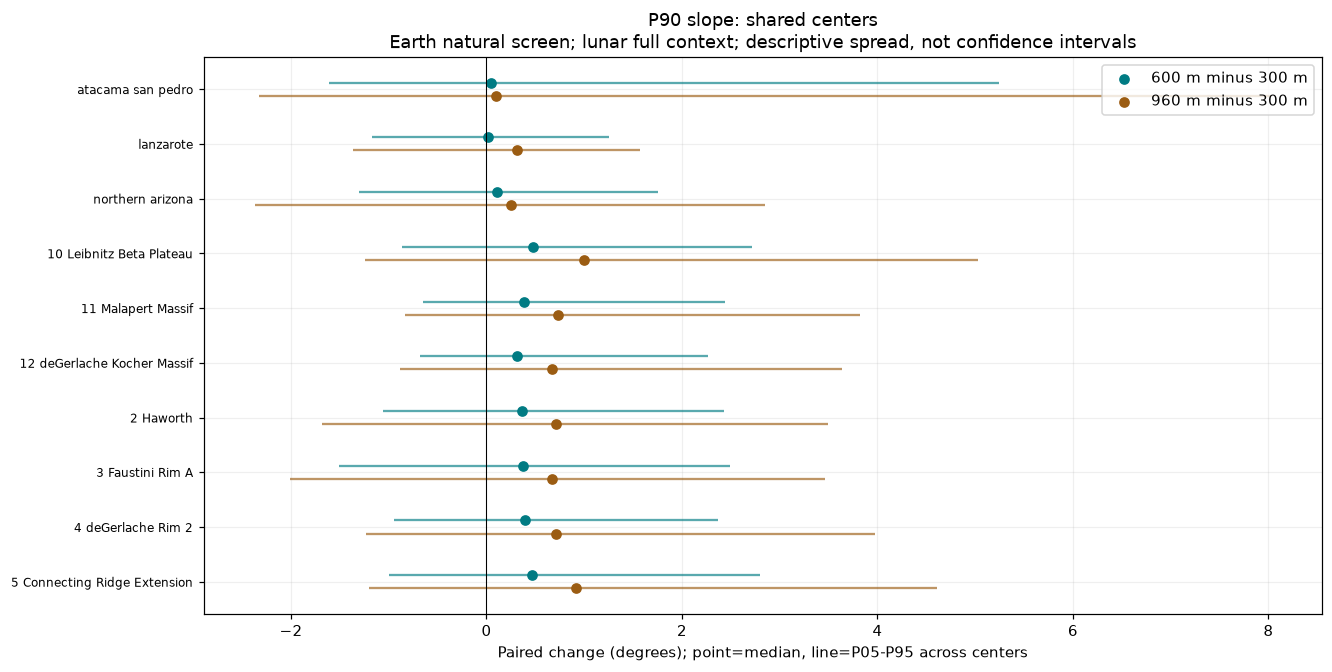

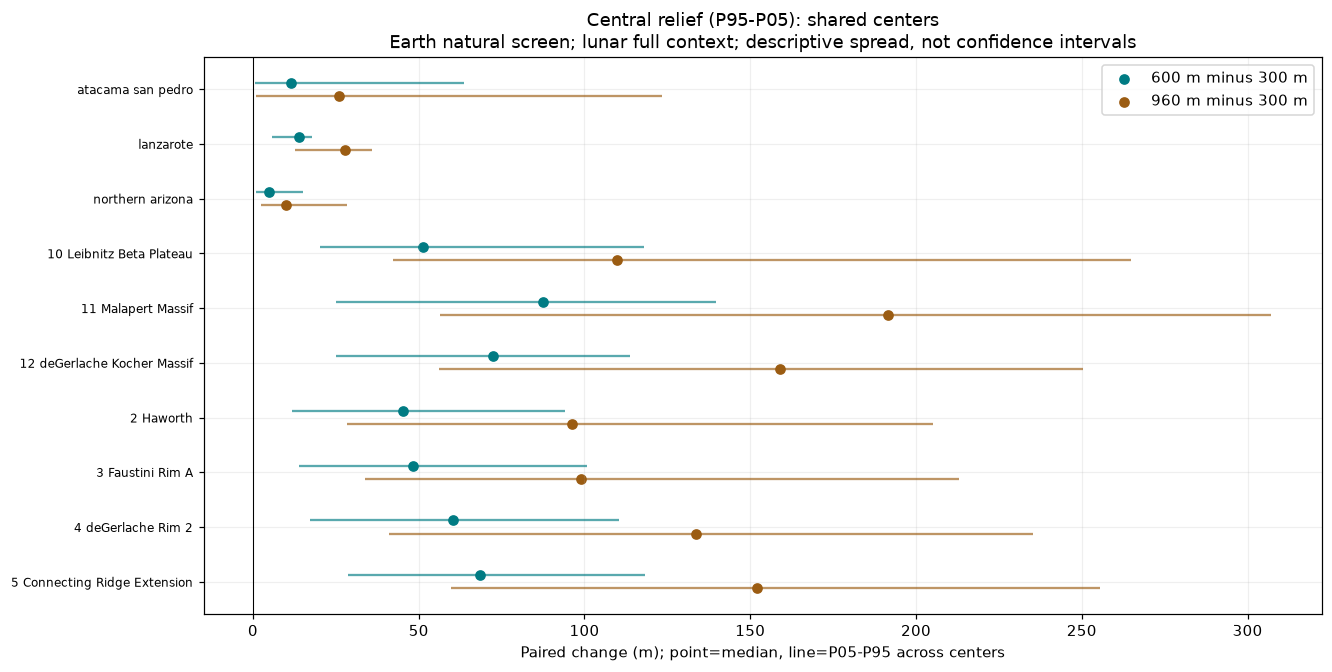

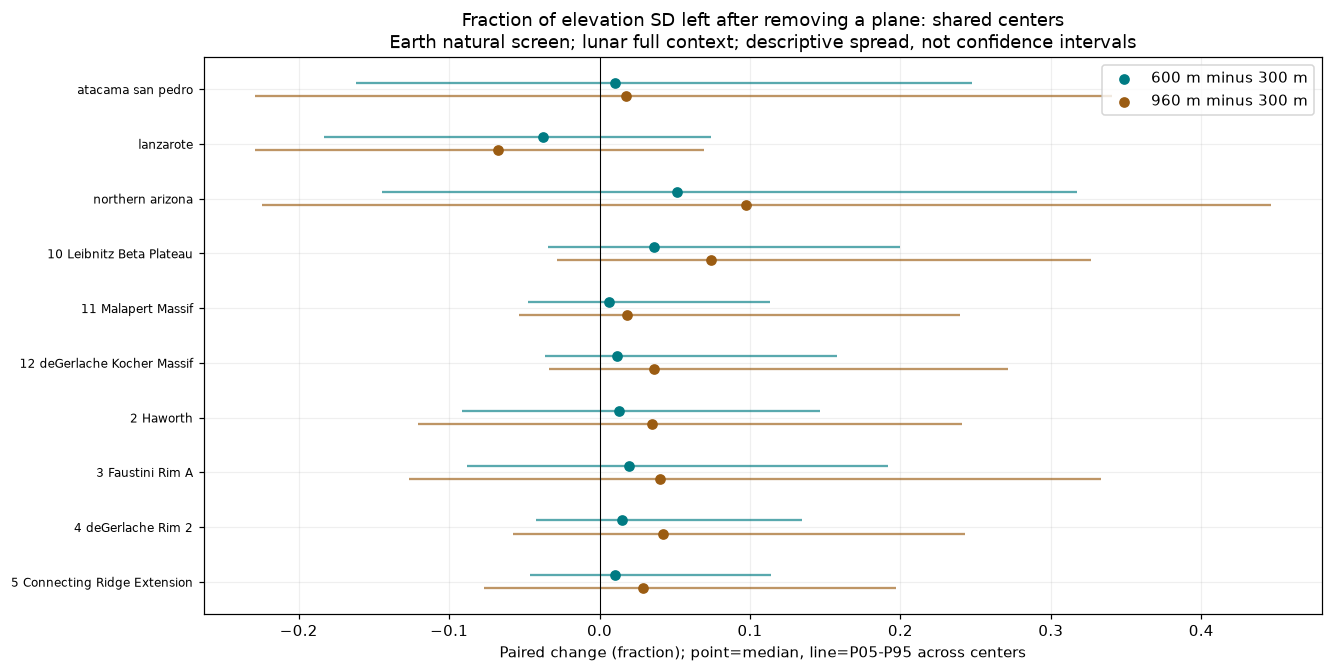

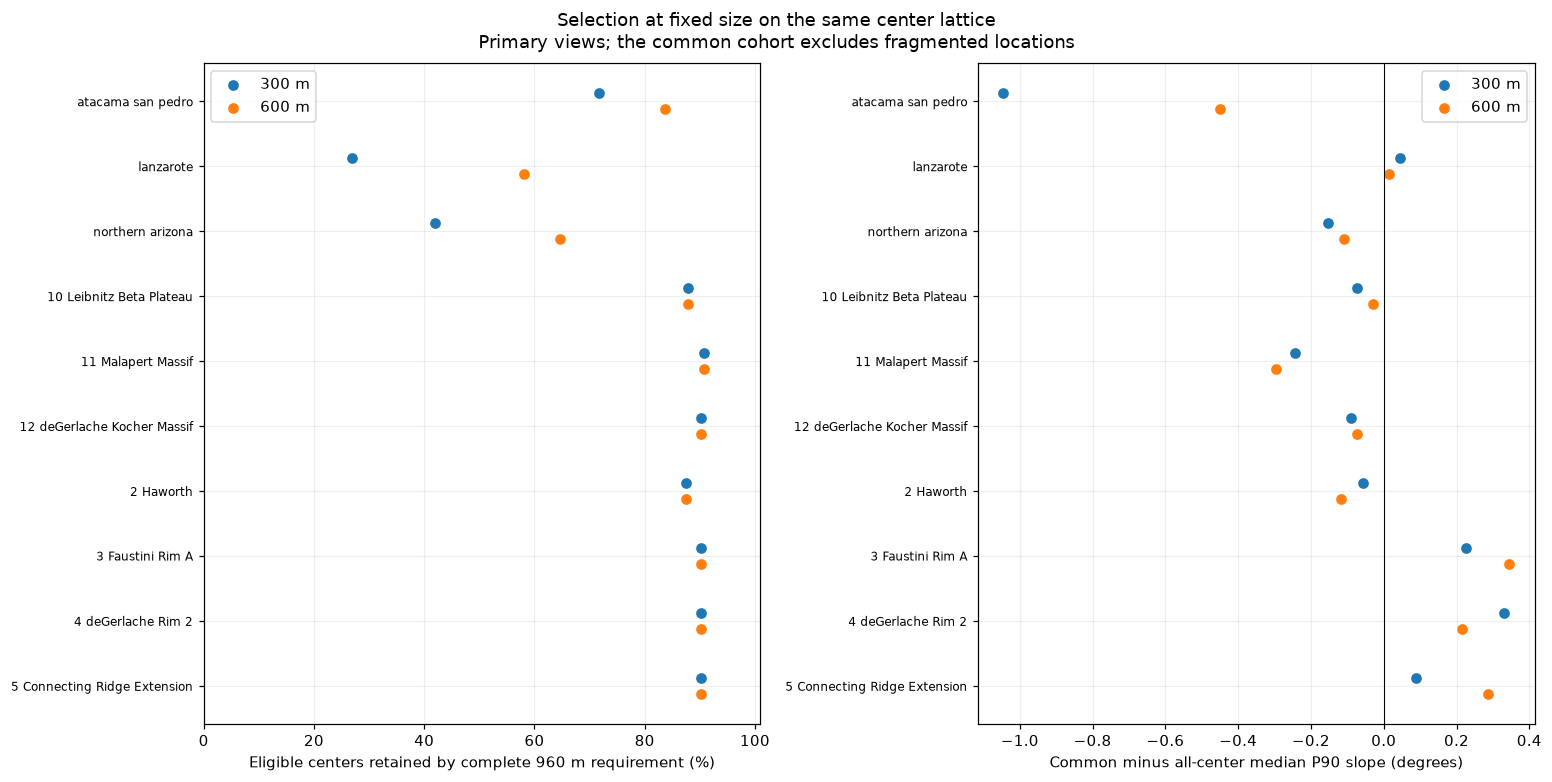

In [4]:
delta_rows: list[dict[str, Any]] = []
selection_rows: list[dict[str, Any]] = []
for _, raw_group in patches.groupby(GROUP, sort=True):
    group = pd.DataFrame(raw_group)
    identity = {name: group.iloc[0][name] for name in GROUP}
    common_group = pd.DataFrame(group.loc[group['common']])
    small = pd.DataFrame(common_group.loc[common_group['size_m'] == 300]).set_index('center_id').sort_index()
    for size in SIZES:
        all_at_size = pd.DataFrame(group.loc[group['size_m'] == size])
        common_at_size = pd.DataFrame(common_group.loc[common_group['size_m'] == size]).set_index('center_id').sort_index()
        assert list(small.index) == list(common_at_size.index)
        for feature in FEATURES:
            all_median = float(all_at_size[feature].median())
            common_median = float(common_at_size[feature].median())
            previous = old_stats[(old_stats['region'] == identity['region'])
                                 & (old_stats['population'] == identity['population'])
                                 & (old_stats['size_m'] == size) & (old_stats['feature'] == feature)]
            selection_rows.append({**identity, 'size_m': size, 'feature': feature,
                                   'eligible_n': len(all_at_size), 'common_n': len(common_at_size),
                                   'all_center_median': all_median, 'common_median': common_median,
                                   'common_minus_all': common_median - all_median,
                                   'previous_lattice_median': float(previous.iloc[0]['median']) if len(previous) else np.nan})
            if size == 300:
                continue
            differences = common_at_size[feature].to_numpy() - small[feature].to_numpy()
            p05, median, p95 = np.quantile(differences, [.05, .5, .95])
            rho = pd.Series(small[feature]).corr(pd.Series(common_at_size[feature]), method='spearman')
            delta_rows.append({**identity, 'from_m': 300, 'to_m': size, 'feature': feature,
                               'centers': len(small), 'delta_p05': p05, 'delta_median': median, 'delta_p95': p95,
                               'difference_of_medians': common_median - float(small[feature].median()),
                               'spearman_across_scales': rho})
deltas = pd.DataFrame(delta_rows)
selection = pd.DataFrame(selection_rows)
deltas.to_csv(OUT / 'paired_scale_changes.csv', index=False)
selection.to_csv(OUT / 'selection_effects.csv', index=False)
primary_mask = deltas['population'].isin(['natural_screen', 'full_context'])
primary_regions = [region for _, region, _ in site_specs]
short_names = [r.replace('A3CLR22_', '').replace('_', ' ') for r in primary_regions]
colors = {600: '#007b83', 960: '#9b5c12'}
for feature, title, unit in [('slope_p90_deg', 'P90 slope', 'degrees'),
                              ('central_relief_m', 'Central relief (P95-P05)', 'm'),
                              ('plane_residual_fraction', 'Fraction of elevation SD left after removing a plane', 'fraction')]:
    fig, ax = plt.subplots(figsize=(12, 6), layout='constrained')
    for offset, size in enumerate([600, 960]):
        selected = pd.DataFrame(deltas.loc[primary_mask & (deltas['to_m'] == size)
                                          & (deltas['feature'] == feature)]).set_index('region').loc[primary_regions]
        positions = np.arange(10) + (offset - .5) * .24
        ax.hlines(positions, selected['delta_p05'], selected['delta_p95'], color=colors[size], alpha=.65)
        ax.scatter(selected['delta_median'], positions, color=colors[size], label=f'{size} m minus 300 m')
    ax.axvline(0, color='black', linewidth=.7)
    ax.set_yticks(range(10), short_names, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel(f'Paired change ({unit}); point=median, line=P05-P95 across centers')
    ax.set_title(f'{title}: shared centers\nEarth natural screen; lunar full context; descriptive spread, not confidence intervals')
    ax.legend()
    save_figure(fig, f'scale_{feature}')

fig, axes = plt.subplots(1, 2, figsize=(14, 7), layout='constrained')
for offset, size in enumerate([300, 600]):
    subset = pd.DataFrame(selection.loc[selection['population'].isin(['natural_screen', 'full_context'])
                                       & (selection['size_m'] == size) & (selection['feature'] == 'slope_p90_deg')])
    subset = subset.set_index('region').loc[primary_regions]
    positions = np.arange(10) + (offset - .5) * .24
    axes[0].scatter(100 * subset['common_n'] / subset['eligible_n'], positions, label=f'{size} m')
    axes[1].scatter(subset['common_minus_all'], positions, label=f'{size} m')
for ax in axes:
    ax.set_yticks(range(10), short_names, fontsize=8)
    ax.invert_yaxis()
    ax.legend()
axes[0].set_xlim(0, 101)
axes[0].set_xlabel('Eligible centers retained by complete 960 m requirement (%)')
axes[1].axvline(0, color='black', linewidth=.7)
axes[1].set_xlabel('Common minus all-center median P90 slope (degrees)')
fig.suptitle('Selection at fixed size on the same center lattice\nPrimary views; the common cohort excludes fragmented locations')
save_figure(fig, 'center_selection')

# Similar summaries, different spatial form?

Use 600 m as an illustrative middle scale, not a selected default. Compare every
unordered pair within each site/view's common cohort (960 m center spacing).
The base screen requires median slope within 1 degree, P90 slope within 2 degrees,
and central relief within max(5 m, 10% of the smaller relief). A second screen
halves every tolerance. These transparent exploratory tolerances are not
analog labels, equipment limits or tuned retrieval distances.

Export every qualifying pair and summary contrasts. Gallery pairs maximize
the difference in plane-residual fraction, with deterministic ties by row/col.
They are intentionally extreme examples, not representative performance.
Local SD contrasts show variation within these tolerance bands; they do not
establish unique information after exact conditioning or predictive benefit.
Lunar views are searched separately, and full-context gallery hatching marks
cells outside the strict complete-feature mask.

In [5]:
pair_rows: list[dict[str, Any]] = []
pair_summary: list[dict[str, Any]] = []
selected_rows: list[dict[str, Any]] = []
at_600 = pd.DataFrame(common_patches.loc[common_patches['size_m'] == 600])
for _, raw_group in at_600.groupby(GROUP, sort=True):
    group = pd.DataFrame(raw_group).sort_values(['center_row', 'center_col']).reset_index(drop=True)
    identity = {name: group.iloc[0][name] for name in GROUP}
    median_slope = group['slope_median_deg'].to_numpy(dtype=float)
    p90 = group['slope_p90_deg'].to_numpy(dtype=float)
    relief = group['central_relief_m'].to_numpy(dtype=float)
    for policy, (median_tol, p90_tol, relief_floor, relief_relative) in PAIR_POLICIES.items():
        qualifying: list[dict[str, Any]] = []
        for i in range(len(group) - 1):
            indices = np.arange(i + 1, len(group))
            keep = ((np.abs(median_slope[indices] - median_slope[i]) <= median_tol)
                    & (np.abs(p90[indices] - p90[i]) <= p90_tol)
                    & (np.abs(relief[indices] - relief[i]) <= np.maximum(relief_floor, relief_relative * np.minimum(relief[i], relief[indices]))))
            for j in indices[keep]:
                first, second = group.iloc[i], group.iloc[int(j)]
                qualifying.append({**identity, 'policy': policy,
                                   'first_id': first['center_id'], 'second_id': second['center_id'],
                                   'plane_fraction_difference': abs(float(first['plane_residual_fraction'] - second['plane_residual_fraction'])),
                                   'local_sd_difference_m': abs(float(first['local_sd_median_m'] - second['local_sd_median_m']))})
        pair_rows.extend(qualifying)
        summary = {**identity, 'policy': policy, 'centers': len(group),
                   'possible_pairs': len(group) * (len(group) - 1) // 2, 'qualifying_pairs': len(qualifying)}
        if qualifying:
            candidates = pd.DataFrame(qualifying)
            for feature in ['plane_fraction_difference', 'local_sd_difference_m']:
                for label, quantile in [('median', .5), ('p95', .95), ('max', 1.)]:
                    summary[f'{feature}_{label}'] = float(candidates[feature].quantile(quantile))
            selected_rows.append(qualifying[int(np.argmax(candidates['plane_fraction_difference'].to_numpy()))])
        pair_summary.append(summary)
pairs = pd.DataFrame(pair_rows)
pair_statistics = pd.DataFrame(pair_summary)
selected_pairs = pd.DataFrame(selected_rows)
pairs.to_csv(OUT / 'qualifying_pairs.csv.gz', index=False, compression='gzip')
pair_statistics.to_csv(OUT / 'pair_statistics.csv', index=False)
selected_pairs.to_csv(OUT / 'selected_pairs.csv', index=False)
display(pair_statistics)
print('Qualifying pair records (base/half overlap):', len(pairs))

,body,region,population,policy,centers,possible_pairs,qualifying_pairs,plane_fraction_difference_median,plane_fraction_difference_p95,plane_fraction_difference_max,local_sd_difference_m_median,local_sd_difference_m_p95,local_sd_difference_m_max
0,earth,atacama_san_pedro,natural_screen,base,3078,4735503,411375,0.078983,0.388289,0.901336,0.307200,0.922226,9.732069
1,earth,atacama_san_pedro,natural_screen,half,3078,4735503,219386,0.066976,0.352614,0.901336,0.154857,0.485691,9.732069
2,earth,lanzarote,natural_screen,base,32,496,190,0.067579,0.218017,0.289376,0.352131,0.994400,1.474460
3,earth,lanzarote,natural_screen,half,32,496,70,0.058487,0.162956,0.274406,0.258463,0.674744,0.874156
4,earth,northern_arizona,natural_screen,base,701,245350,71852,0.180149,0.597564,0.923374,0.413771,1.028273,3.796288
5,earth,northern_arizona,natural_screen,half,701,245350,26796,0.150078,0.544313,0.913888,0.221587,0.588652,3.796288
6,moon,A3CLR22_10_Leibnitz_Beta_Plateau,full_context,base,225,25200,1311,0.036667,0.198108,0.614537,0.812553,1.908586,2.713951
7,moon,A3CLR22_10_Leibnitz_Beta_Plateau,full_context,half,225,25200,354,0.027463,0.143570,0.435232,0.465452,1.276059,2.027328
8,moon,A3CLR22_10_Leibnitz_Beta_Plateau,image_supported,base,68,2278,417,0.018499,0.071157,0.156631,0.908539,1.965320,2.713951
9,moon,A3CLR22_10_Leibnitz_Beta_Plateau,image_supported,half,68,2278,148,0.016146,0.043400,0.095343,0.397141,1.108367,1.490959


Qualifying pair records (base/half overlap): 800002


# Findings-led check: absolute amplitude and lunar support

The first execution selected Earth examples with only about 2 m central relief,
and lunar full-context examples with extensive strict-mask exclusions. A large
dimensionless contrast alone can therefore mislead. Preserve those examples,
then count matched pairs requiring both central reliefs >=10, >=20 or >=40 m.
These are sensitivity scenarios, not source-error bounds or mission thresholds.
Export the count and contrast distribution at every floor, including zeros.
For a second gallery use half tolerances, the 20 m scenario, and image-supported
lunar cohorts. This conditions on a different terrain population; it cannot
estimate an effect of source support. The 20 m scenario is illustrative.

In [6]:
amplitude_rows: list[dict[str, Any]] = []
amplitude_selected: list[dict[str, Any]] = []
lookup = at_600.set_index('center_id')
first_relief = pd.Series(pairs['first_id']).map(pd.Series(lookup['central_relief_m'])).to_numpy(dtype=float)
second_relief = pd.Series(pairs['second_id']).map(pd.Series(lookup['central_relief_m'])).to_numpy(dtype=float)
minimum_relief = np.minimum(first_relief, second_relief)
for relief_floor in [10, 20, 40]:
    filtered_pairs = pd.DataFrame(pairs.loc[minimum_relief >= relief_floor])
    for original in pair_statistics.to_dict('records'):
        subset = pd.DataFrame(filtered_pairs.loc[(filtered_pairs['region'] == original['region'])
                                                 & (filtered_pairs['population'] == original['population'])
                                                 & (filtered_pairs['policy'] == original['policy'])])
        entry = {name: original[name] for name in [*GROUP, 'policy']}
        entry.update({'minimum_central_relief_m': relief_floor, 'unfiltered_pairs': original['qualifying_pairs'],
                      'qualifying_pairs': len(subset)})
        for label, quantile in [('median', .5), ('p95', .95), ('max', 1.)]:
            entry[f'plane_fraction_difference_{label}'] = float(subset['plane_fraction_difference'].quantile(quantile)) if len(subset) else np.nan
        amplitude_rows.append(entry)
        if relief_floor == 20 and original['policy'] == 'half' and len(subset):
            selected = subset.iloc[int(np.argmax(subset['plane_fraction_difference'].to_numpy()))].to_dict()
            amplitude_selected.append({**selected, 'minimum_central_relief_m': relief_floor})
amplitude_statistics = pd.DataFrame(amplitude_rows)
amplitude_gallery = pd.DataFrame(amplitude_selected)
amplitude_statistics.to_csv(OUT / 'amplitude_sensitivity.csv', index=False)
amplitude_gallery.to_csv(OUT / 'amplitude_selected_pairs.csv', index=False)
display(amplitude_statistics)

,body,region,population,policy,minimum_central_relief_m,unfiltered_pairs,qualifying_pairs,plane_fraction_difference_median,plane_fraction_difference_p95,plane_fraction_difference_max
0,earth,atacama_san_pedro,natural_screen,base,10,411375,245556,0.070160,0.324332,0.745364
1,earth,atacama_san_pedro,natural_screen,half,10,219386,94117,0.048167,0.211862,0.661863
2,earth,lanzarote,natural_screen,base,10,190,190,0.067579,0.218017,0.289376
3,earth,lanzarote,natural_screen,half,10,70,70,0.058487,0.162956,0.274406
4,earth,northern_arizona,natural_screen,base,10,71852,23154,0.151540,0.485884,0.837455
...,...,...,...,...,...,...,...,...,...,...
97,moon,A3CLR22_4_deGerlache_Rim_2,image_supported,half,40,300,300,0.016435,0.054037,0.155155
98,moon,A3CLR22_5_Connecting_Ridge_Extension,full_context,base,40,4124,4116,0.028101,0.118812,0.411811
99,moon,A3CLR22_5_Connecting_Ridge_Extension,full_context,half,40,1110,1109,0.021429,0.105251,0.201017
100,moon,A3CLR22_5_Connecting_Ridge_Extension,image_supported,base,40,1687,1687,0.017705,0.092093,0.185564


# Selected spatial contrasts

Every panel is 600 m square. Color limits are shared within each figure and
labelled in physical units; limits vary between figures to show low relief.
Elevation is centered per patch for display. A/B are ordered by grid position,
not quality. Read absolute residual RMS alongside the dimensionless fraction.
Counts and full pair distributions above show how selective these examples are.
Full-context lunar heights can be prior-dominated; the hatching is a support
warning, not proof of bad heights. Strict-view comparisons are in the tables.

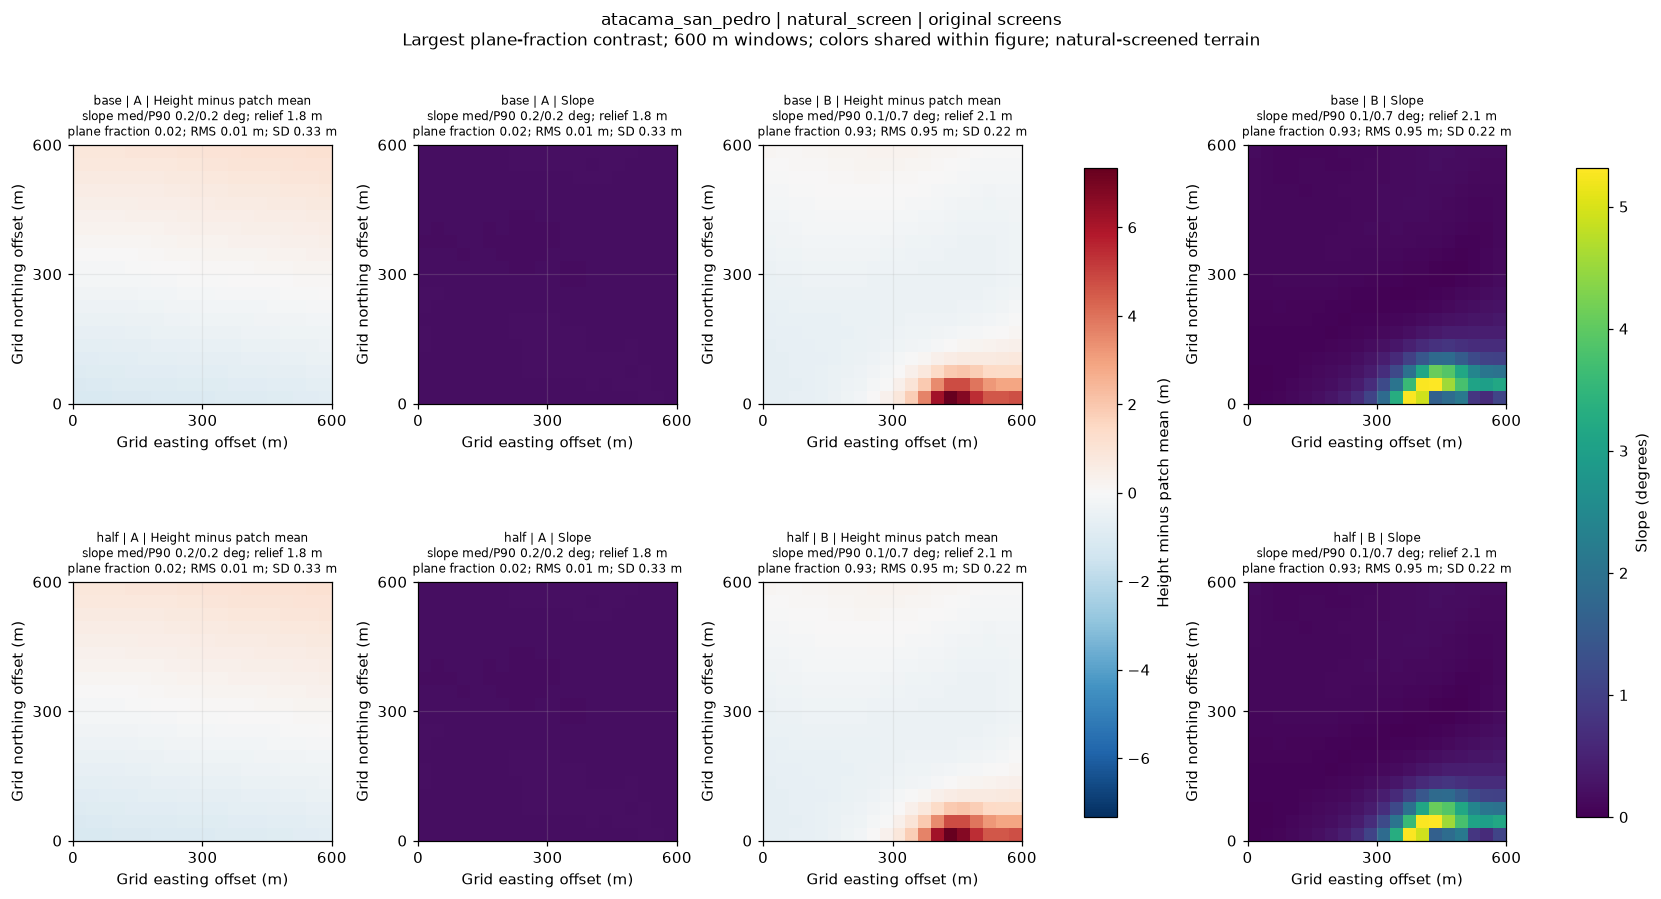

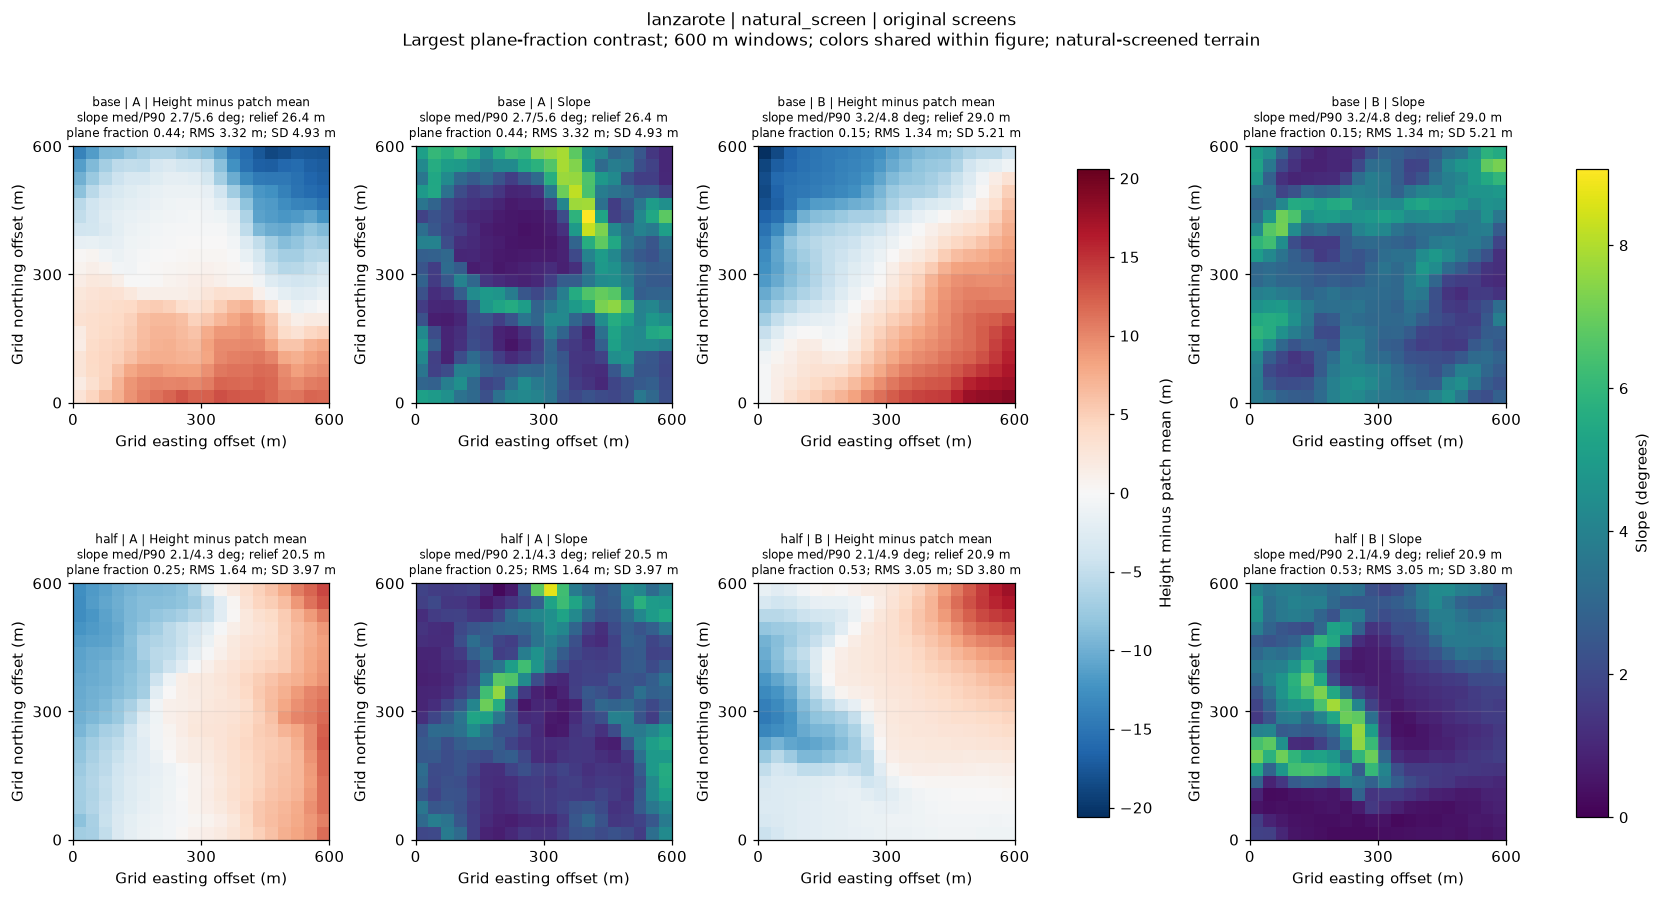

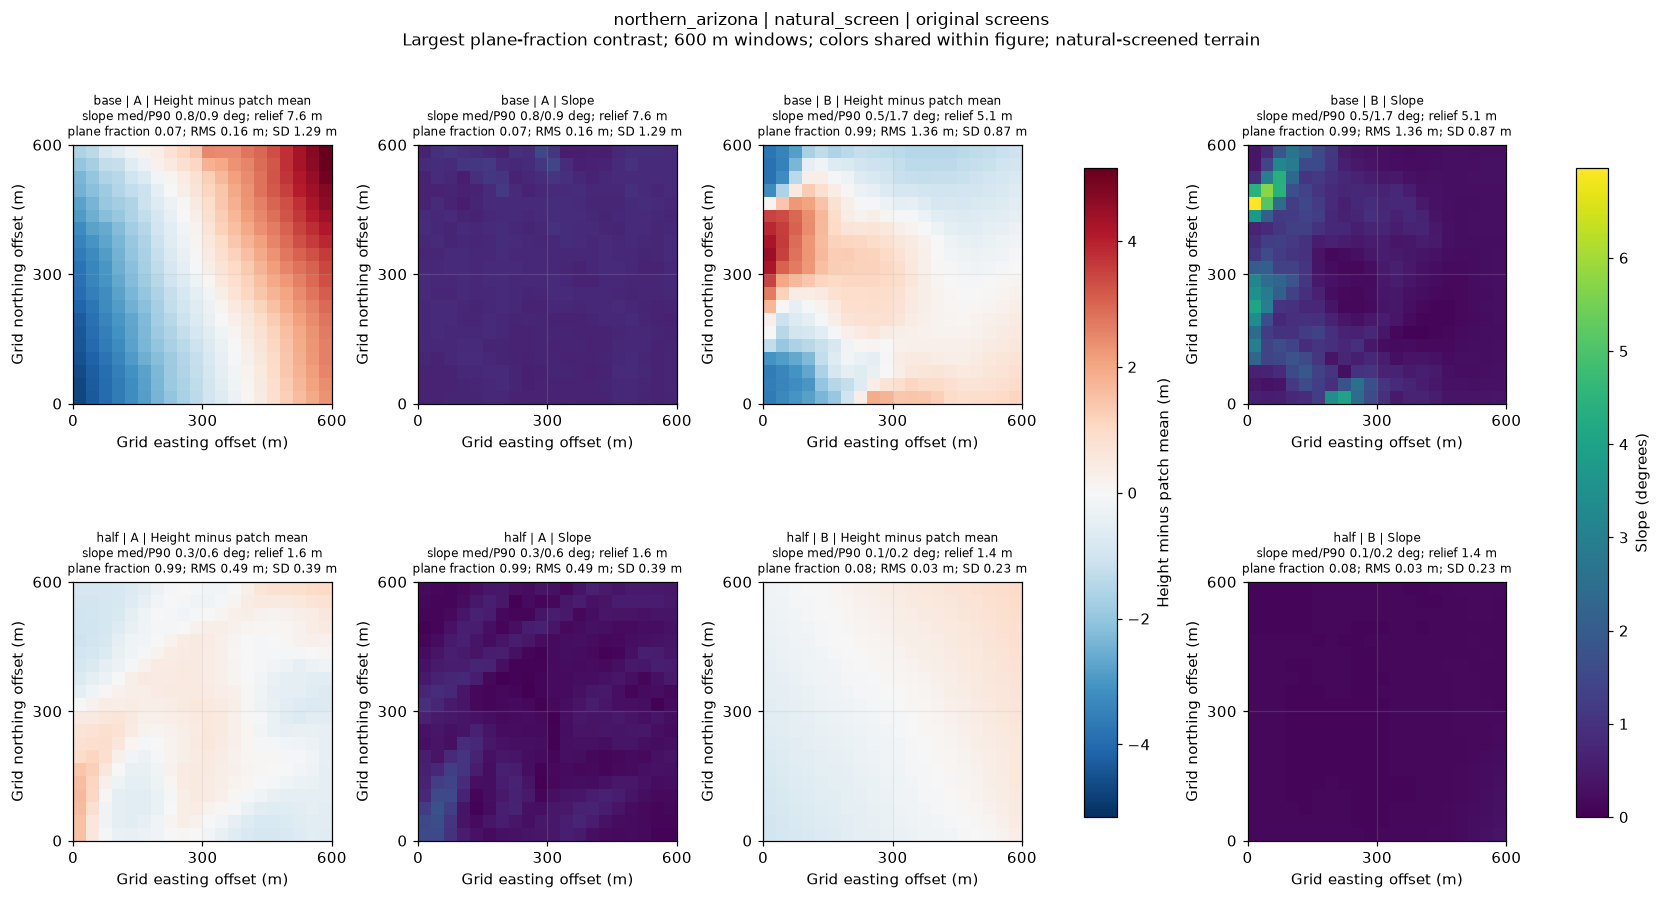

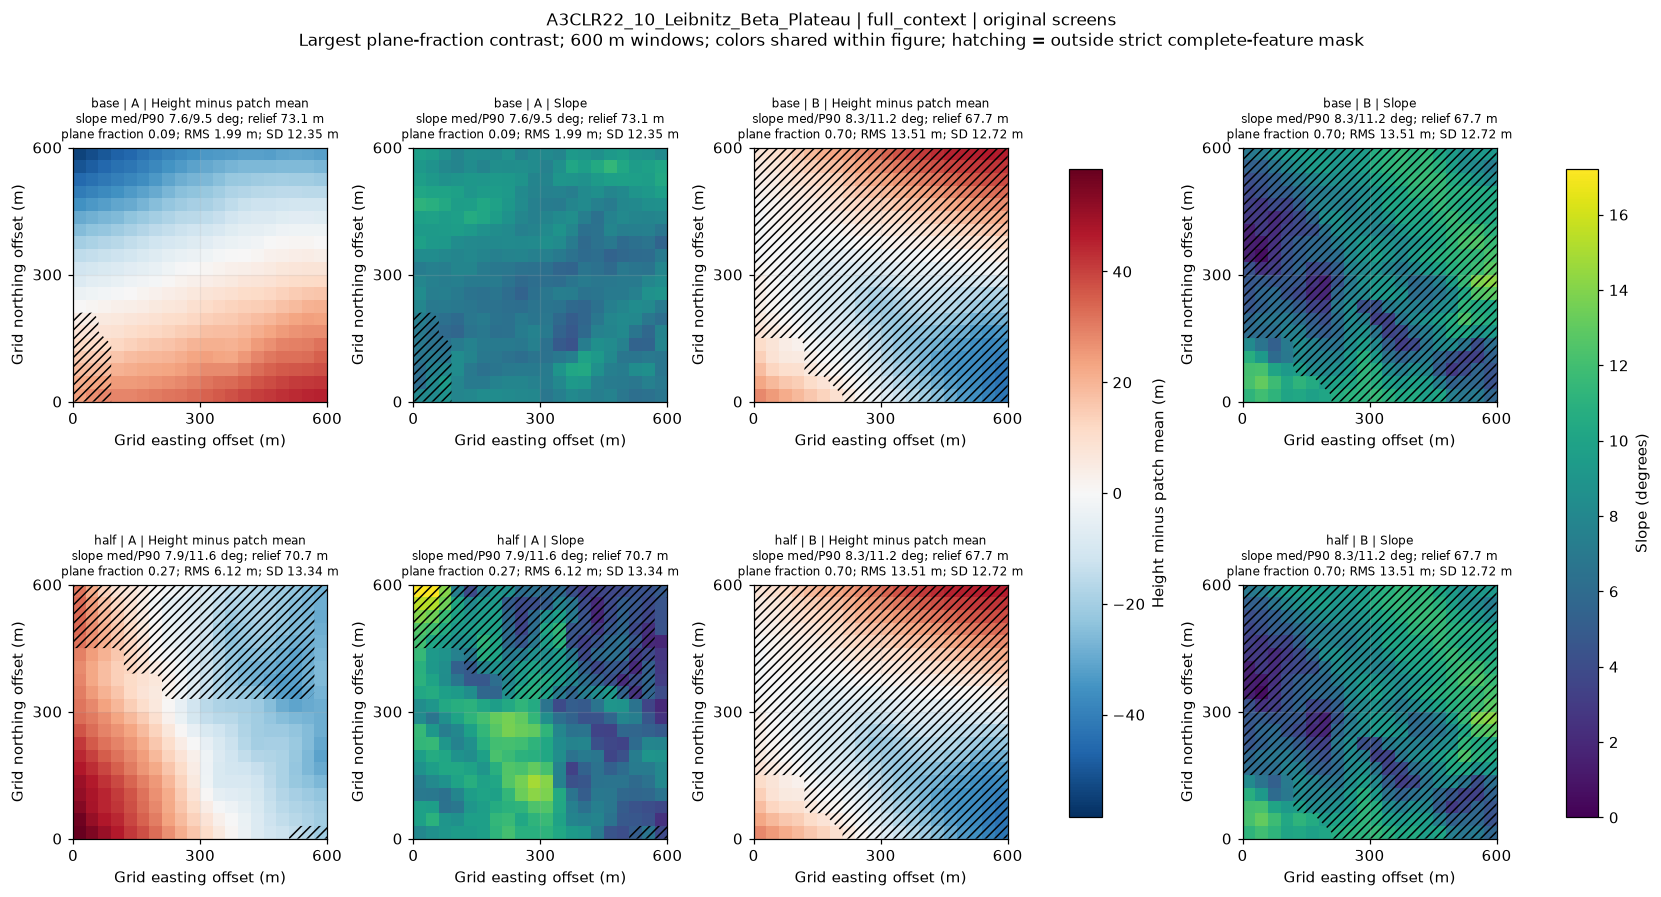

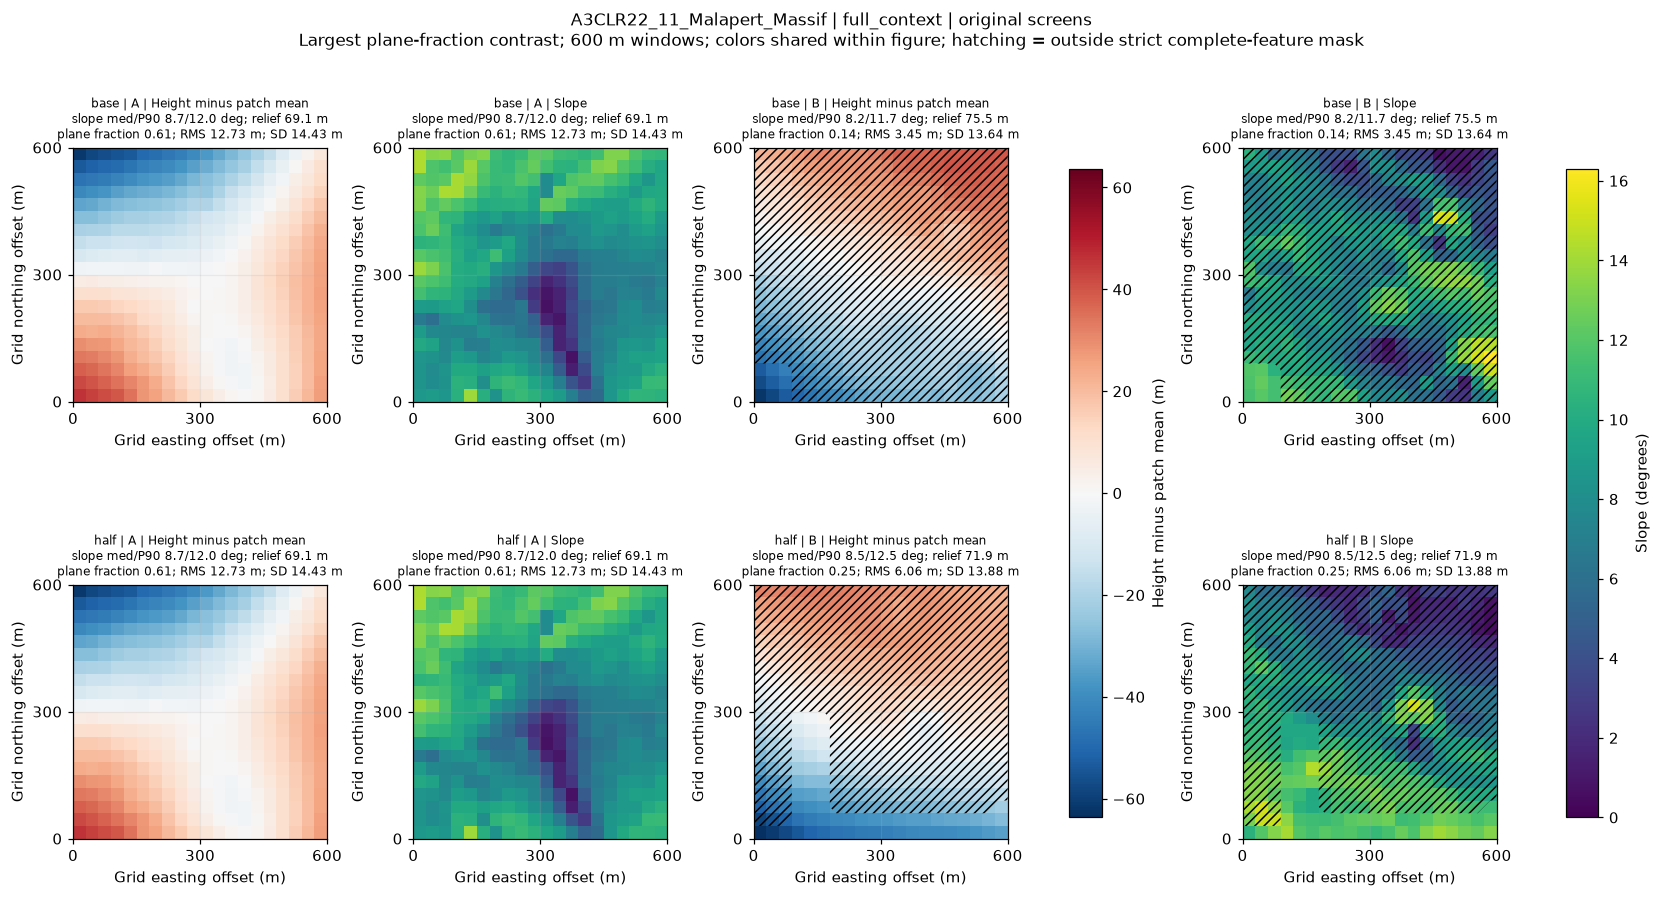

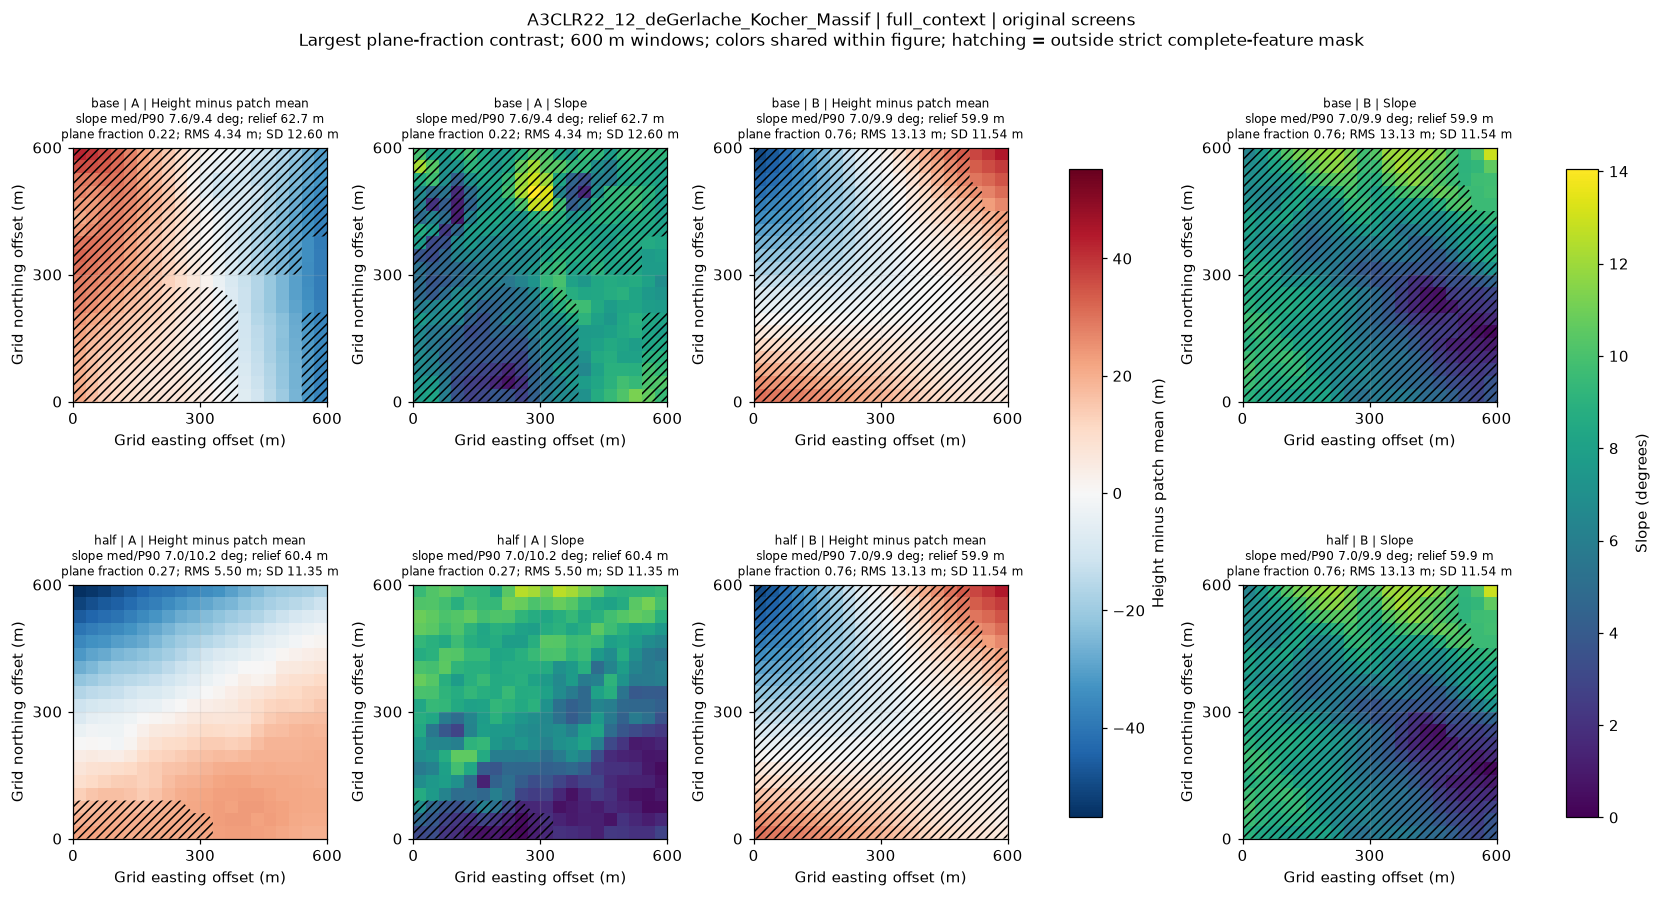

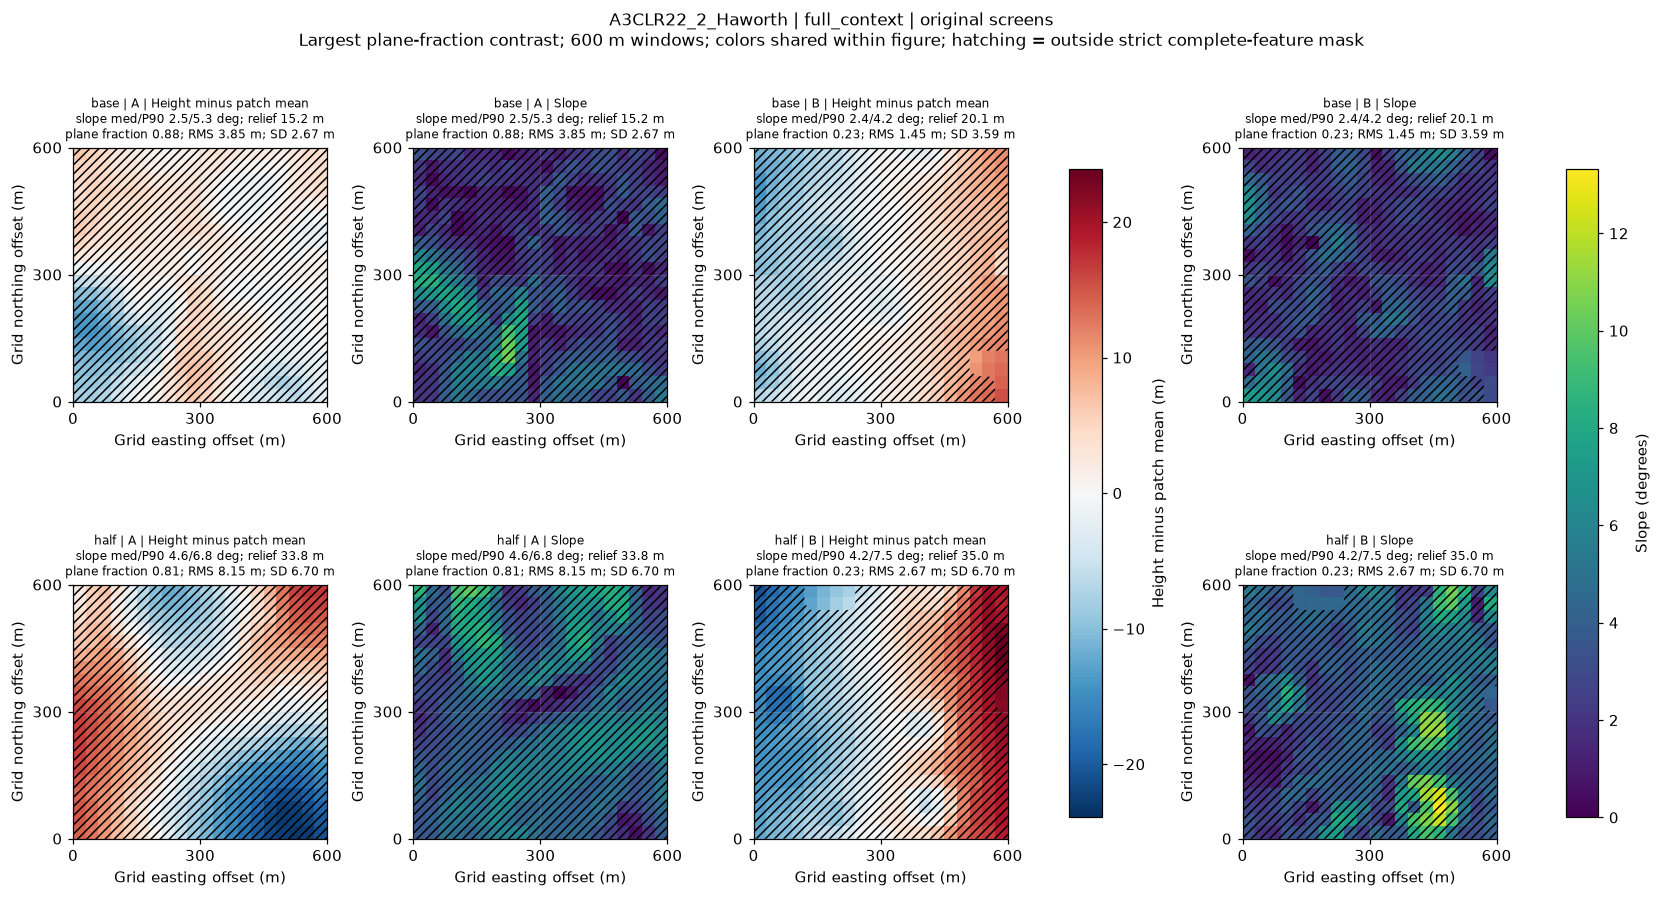

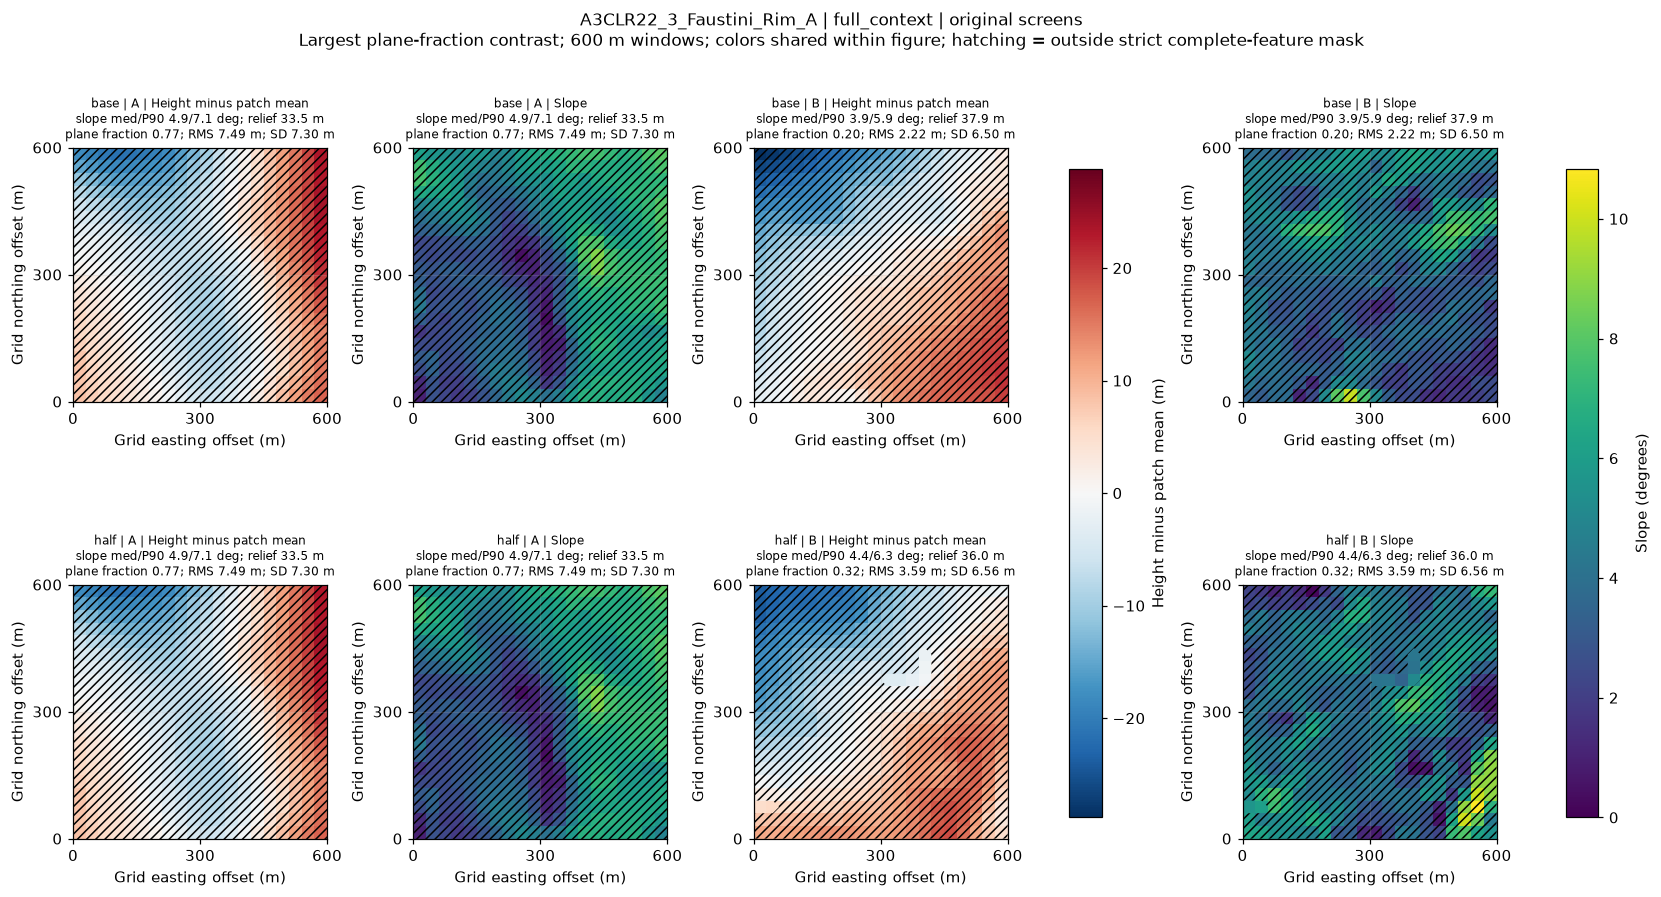

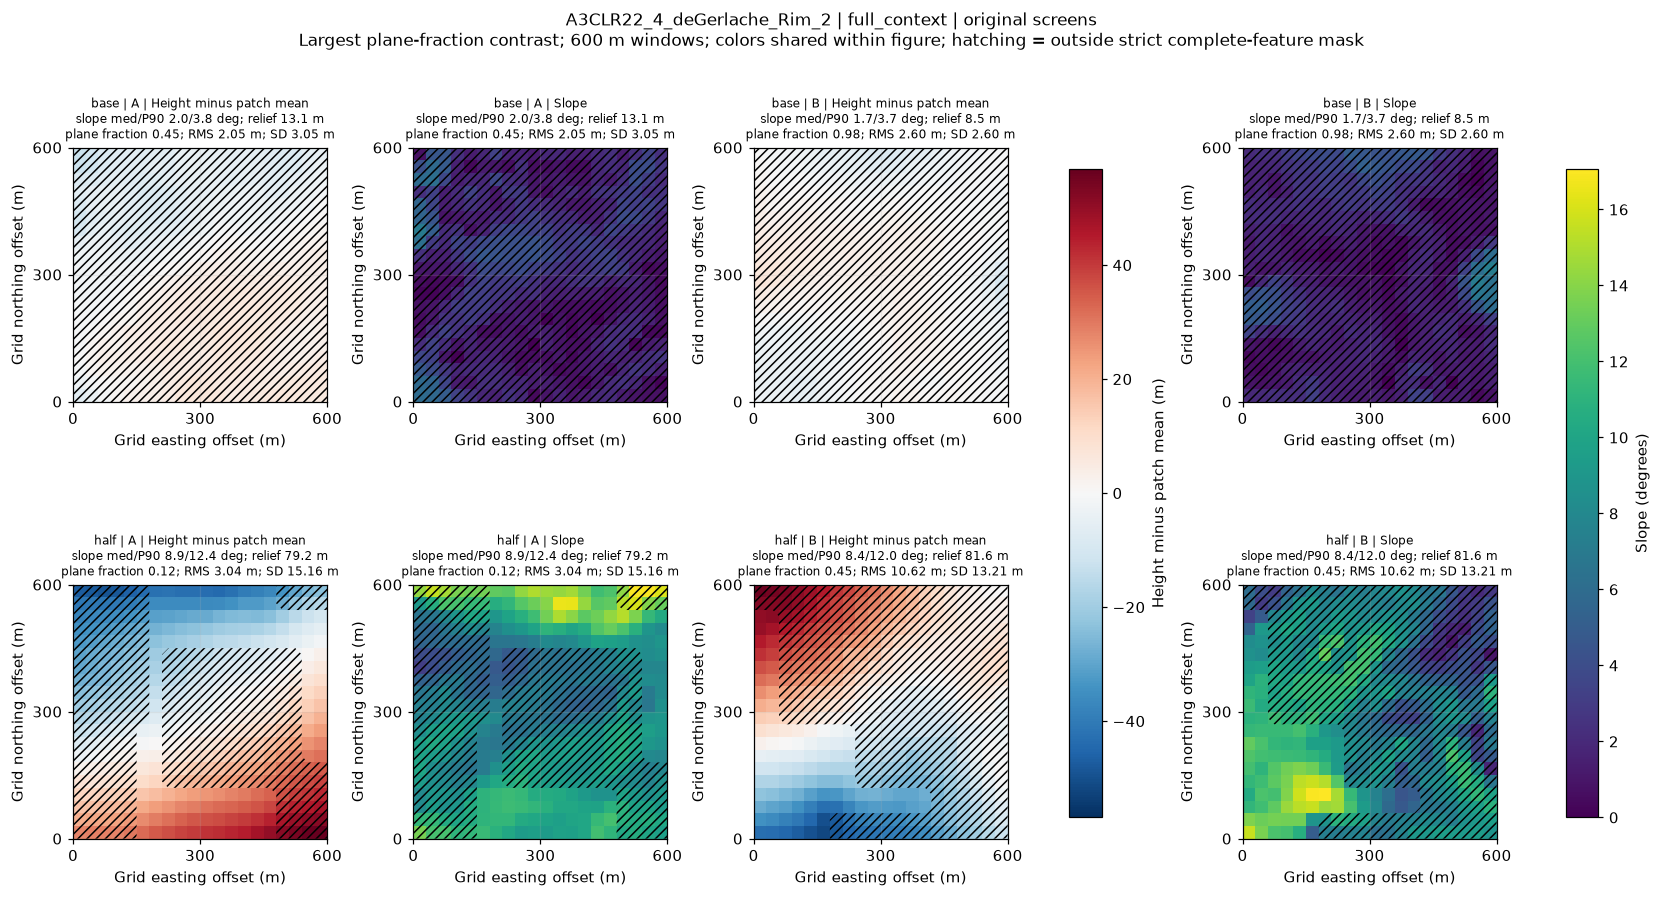

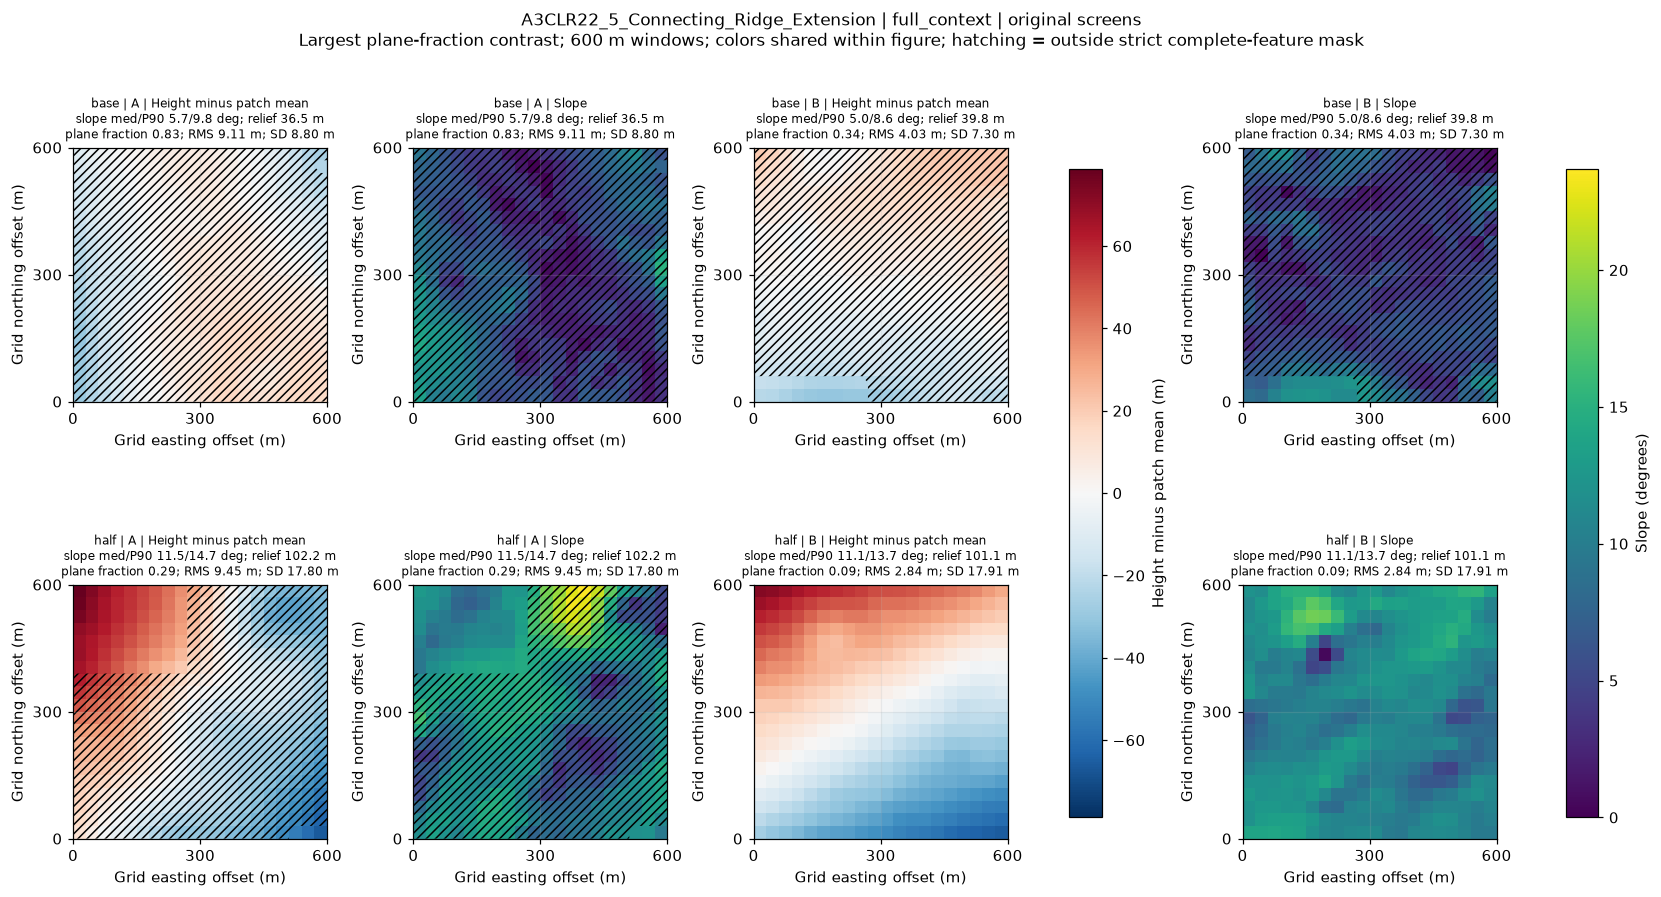

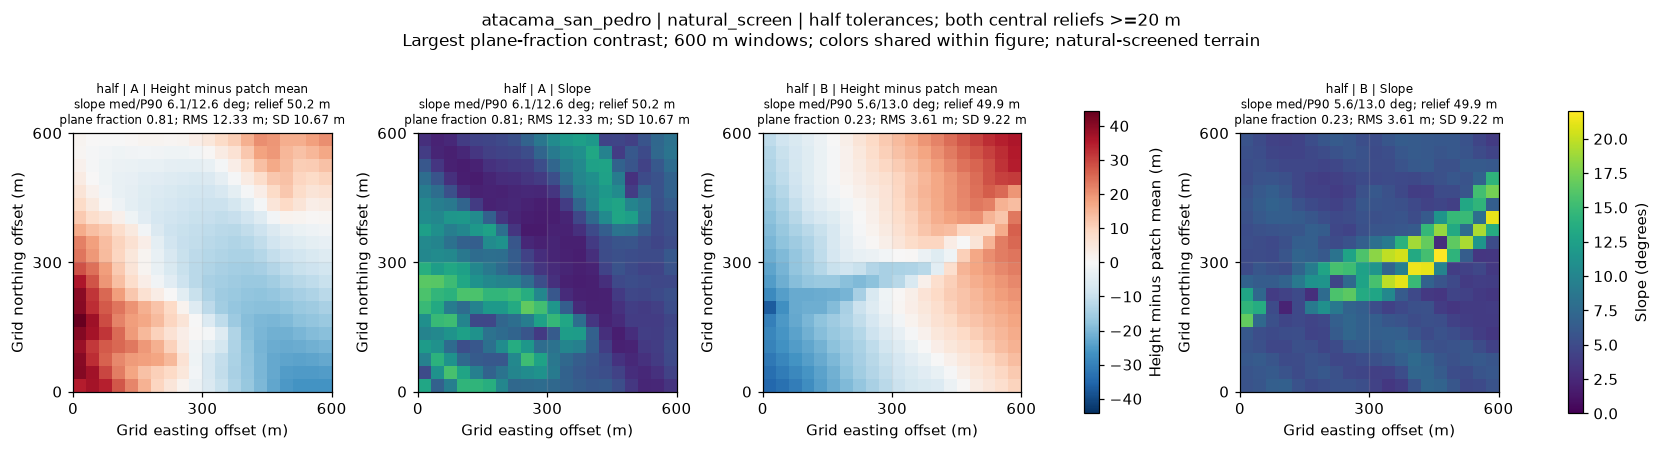

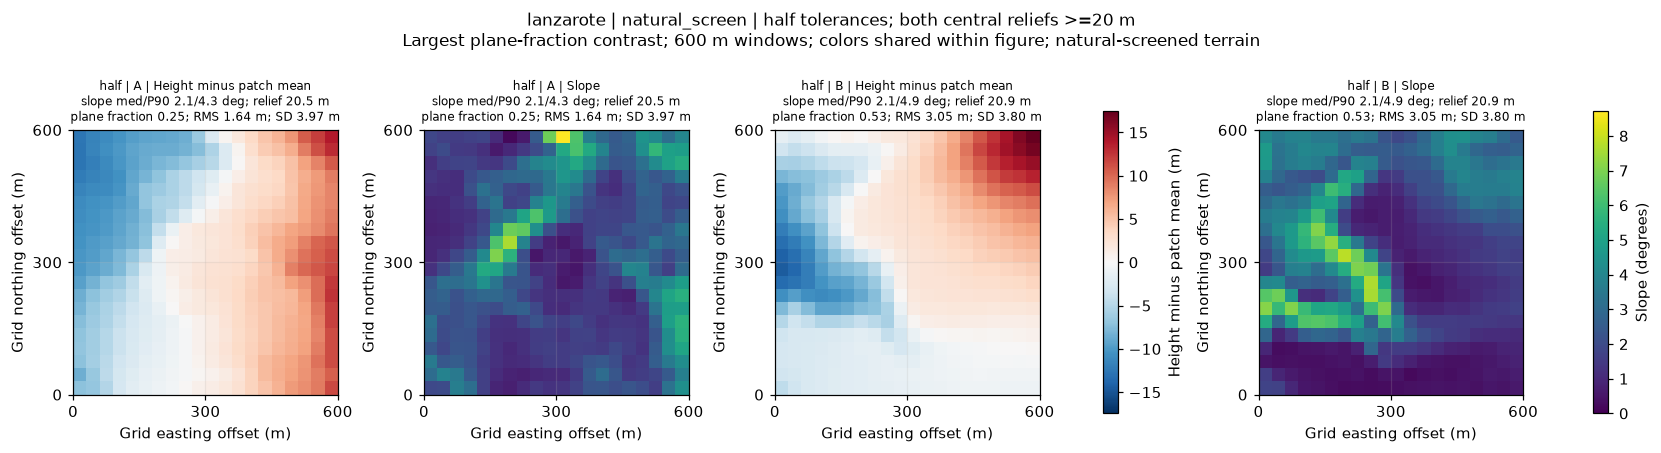

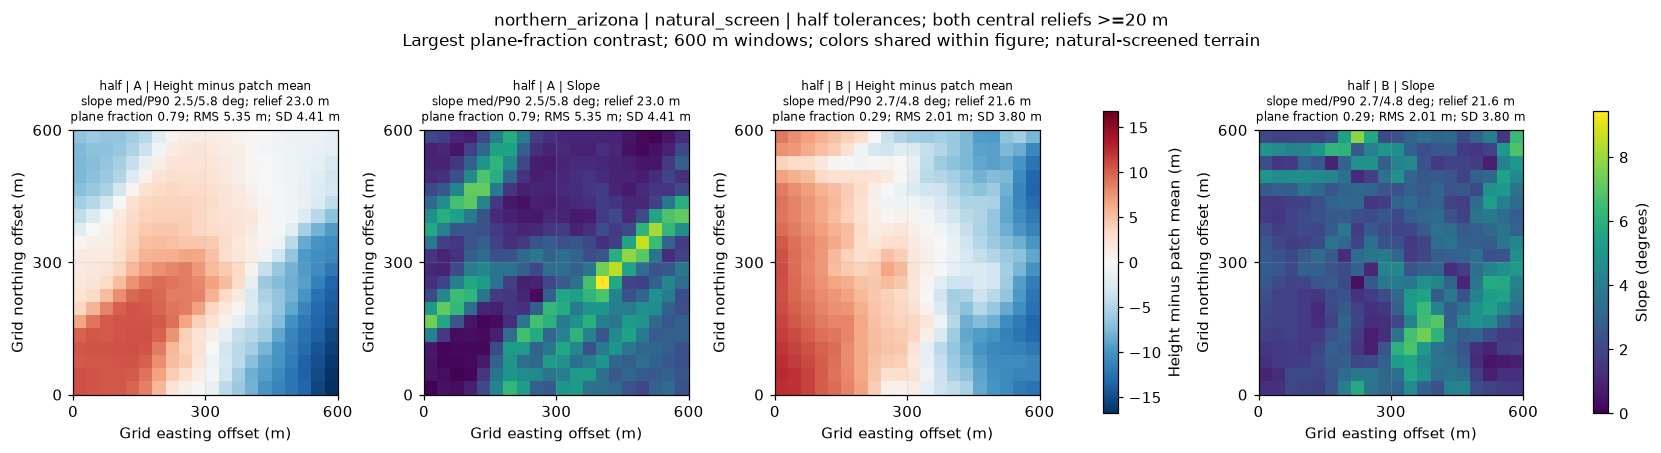

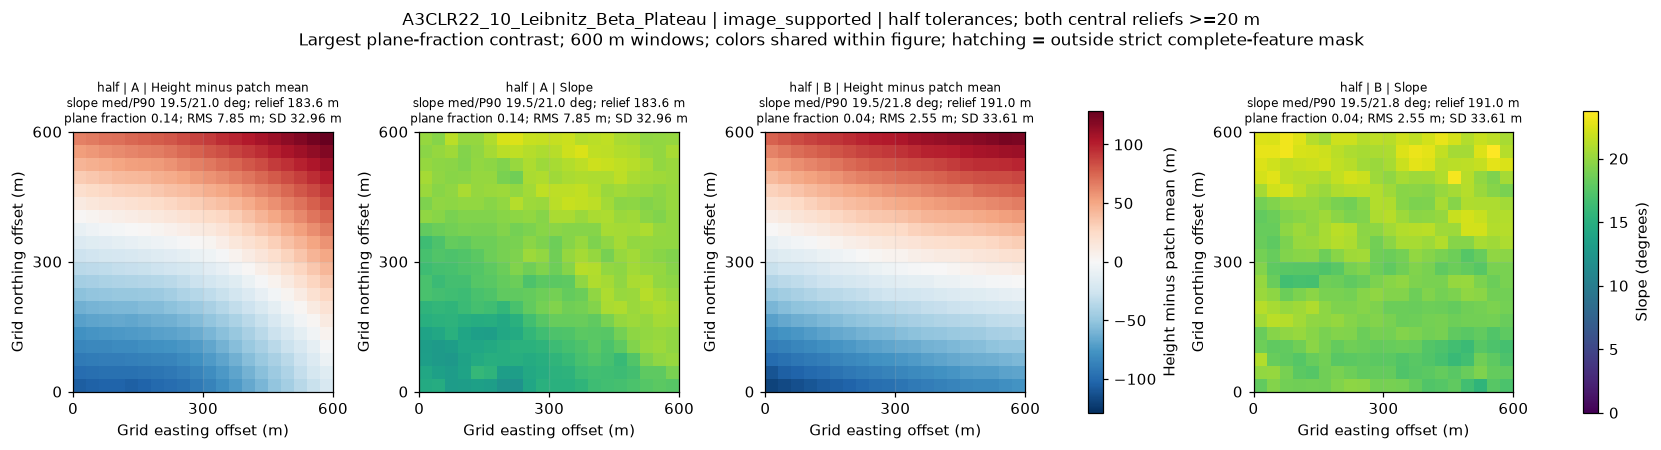

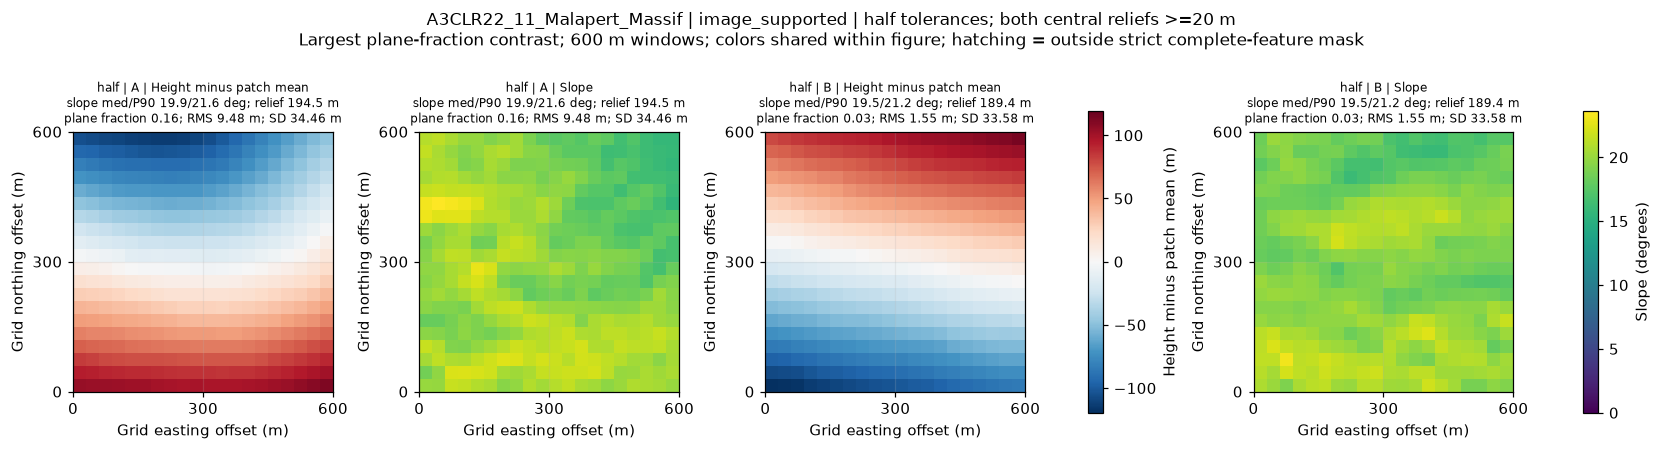

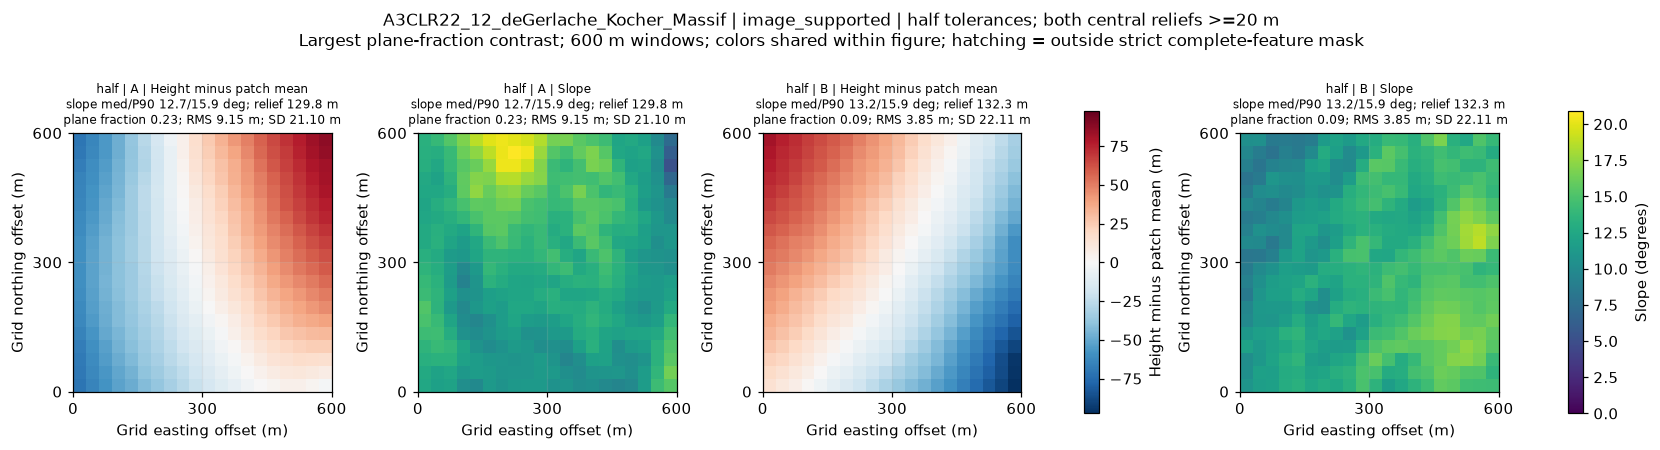

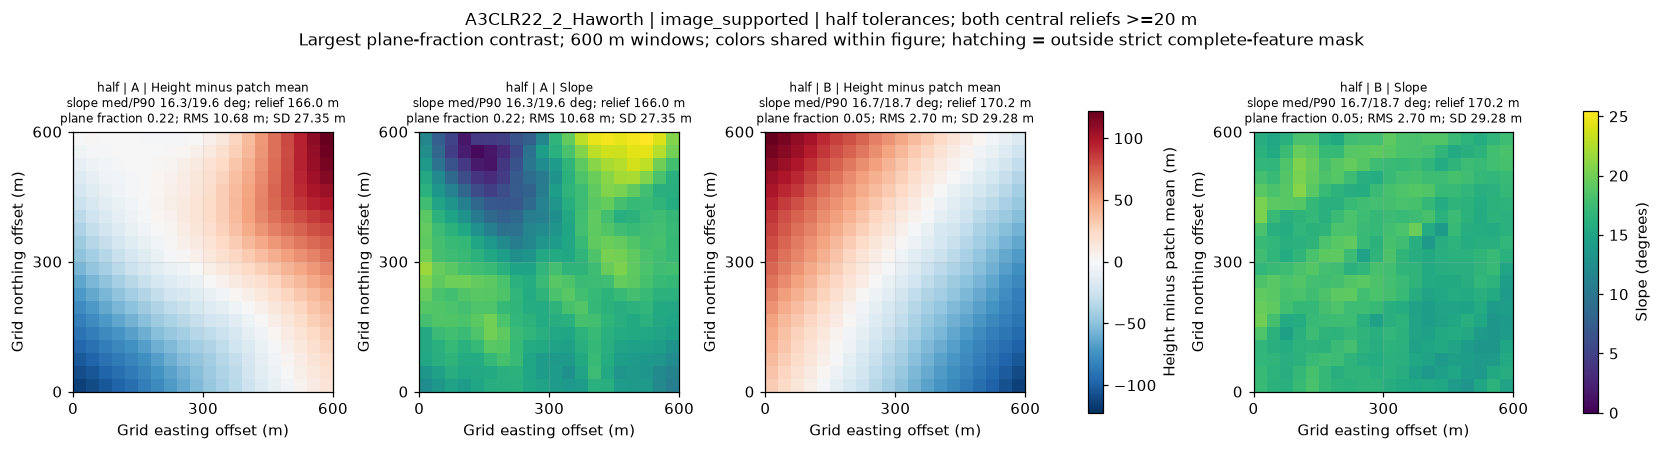

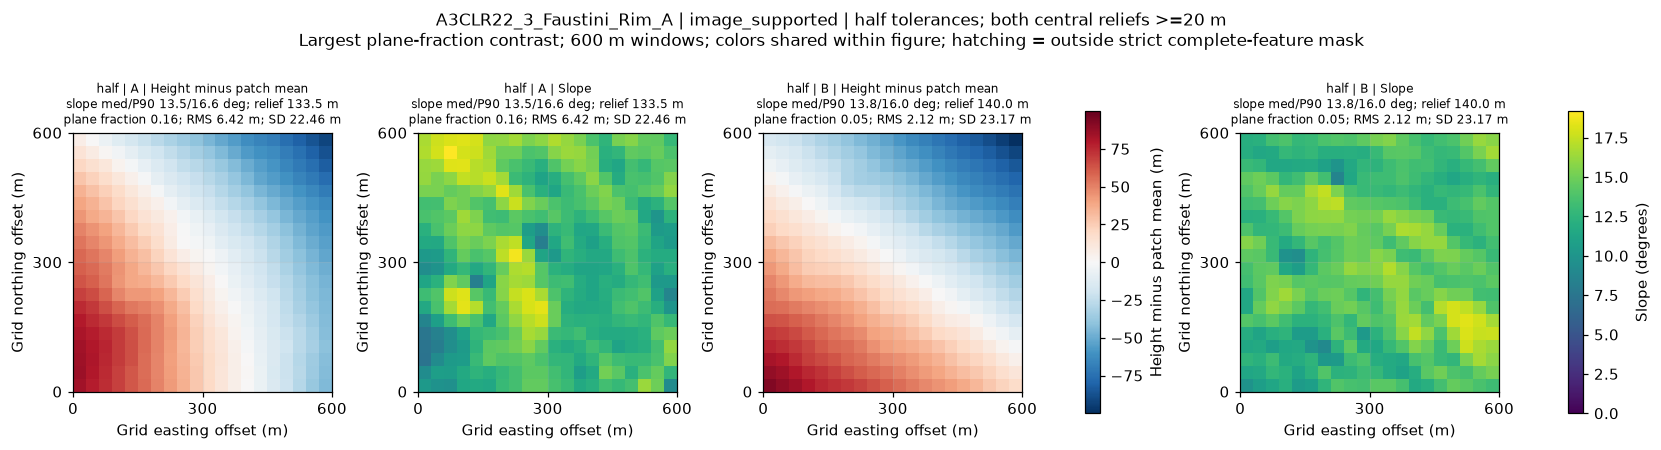

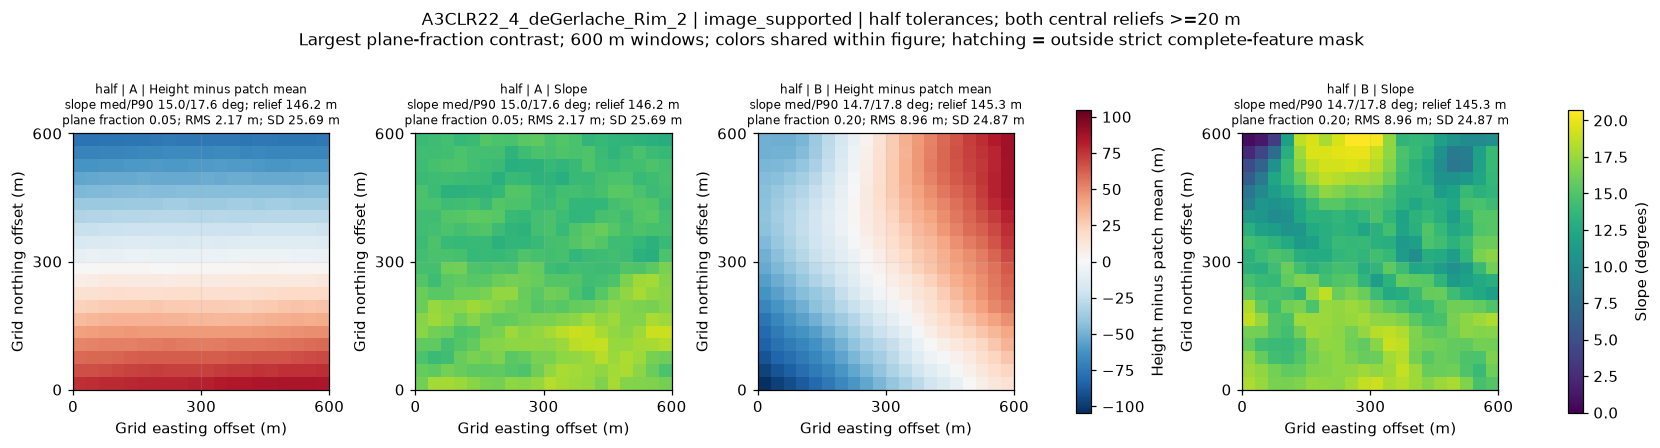

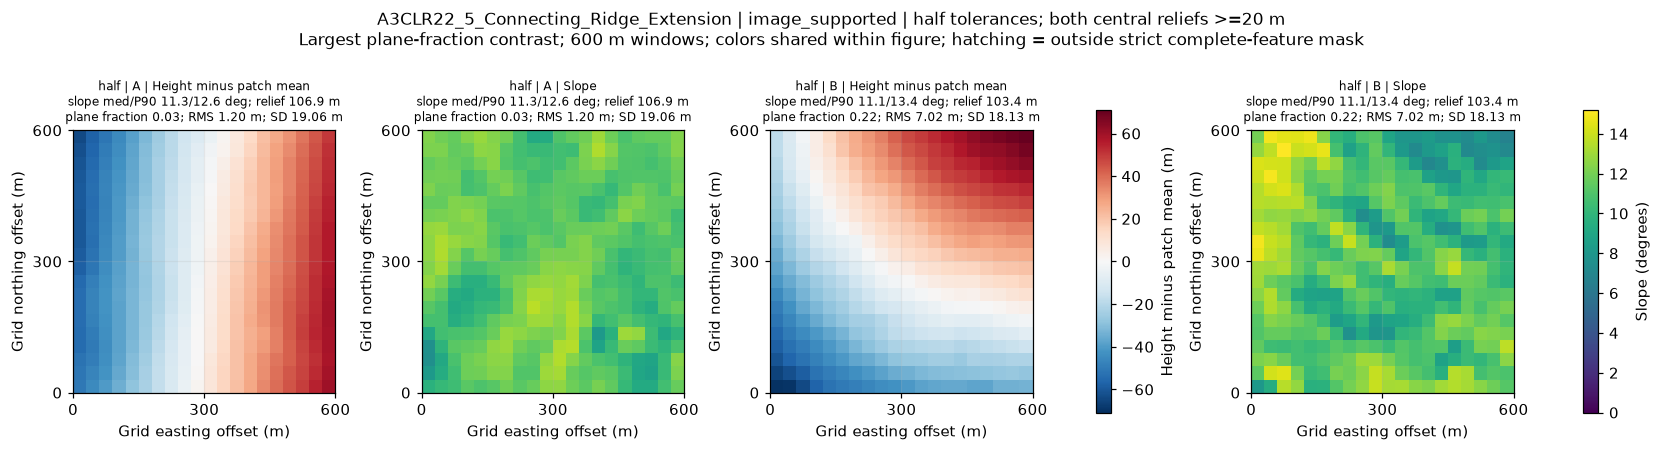

In [7]:
gallery_rows: list[dict[str, Any]] = []
primary_pairs = pd.DataFrame(selected_pairs.loc[selected_pairs['population'].isin(['natural_screen', 'full_context'])])
gallery_specs = [(body, region, 'natural_screen' if body == 'earth' else 'full_context', 'original')
                 for body, region, _ in site_specs]
gallery_specs += [(body, region, 'natural_screen' if body == 'earth' else 'image_supported', 'amplitude')
                  for body, region, _ in site_specs]
for body, region, population, gallery_kind in gallery_specs:
    source_pairs = primary_pairs if gallery_kind == 'original' else amplitude_gallery
    rows = pd.DataFrame(source_pairs.loc[(source_pairs['region'] == region)
                                         & (source_pairs['population'] == population)]).sort_values('policy')
    if rows.empty:
        continue
    folder = layer_folders[region, population]
    elevation, _ = read_layer(folder / 'elevation_m.tif')
    slope, _ = read_layer(folder / 'slope_deg.tif')
    strict = read_layer(strict_paths[region])[0] if body == 'moon' else None
    elevation_limit = slope_limit = 0.
    for name in ['first_id', 'second_id']:
        for identifier in rows[name]:
            patch = lookup.loc[identifier]
            row, col = int(patch['row']), int(patch['col'])
            window = np.s_[row:row + 20, col:col + 20]
            elevation_limit = max(elevation_limit, float(np.abs(elevation[window] - float(patch['elevation_mean_m'])).max()))
            slope_limit = max(slope_limit, float(slope[window].max()))
    elevation_limit, slope_limit = max(elevation_limit, 1e-6), max(slope_limit, 1e-6)
    fig, axes = plt.subplots(len(rows), 4, figsize=(15, 4.2 * len(rows)), squeeze=False, layout='constrained')
    elevation_image = slope_image = None
    for row_index, pair in enumerate(rows.to_dict('records')):
        for pair_index, identifier in enumerate([pair['first_id'], pair['second_id']]):
            patch = lookup.loc[identifier]
            row, col = int(patch['row']), int(patch['col'])
            window = np.s_[row:row + 20, col:col + 20]
            heights = elevation[window] - float(patch['elevation_mean_m'])
            unsupported = (strict[window] != 1) if strict is not None else np.zeros((20, 20), dtype=bool)
            gallery_rows.append({**patch.to_dict(), 'center_id': identifier, 'gallery_kind': gallery_kind,
                                 'policy': pair['policy'], 'pair_member': 'AB'[pair_index],
                                 'elevation_color_limit_m': elevation_limit, 'slope_color_limit_deg': slope_limit,
                                 'strict_complete_fraction': float(1 - unsupported.mean()) if strict is not None else np.nan})
            for channel_index, values in enumerate([heights, slope[window]]):
                ax = axes[row_index, 2 * pair_index + channel_index]
                if channel_index == 0:
                    elevation_image = ax.imshow(values, extent=(0, 600, 0, 600), cmap='RdBu_r', vmin=-elevation_limit, vmax=elevation_limit)
                else:
                    slope_image = ax.imshow(values, extent=(0, 600, 0, 600), cmap='viridis', vmin=0, vmax=slope_limit)
                if unsupported.any():
                    axis_positions = np.r_[0, np.arange(15, 600, 30), 600]
                    ax.contourf(axis_positions, axis_positions, np.pad(unsupported[::-1], 1, mode='edge'),
                                levels=[.5, 1.5], colors='none', hatches=['////'])
                ax.set_xticks([0, 300, 600])
                ax.set_yticks([0, 300, 600])
                ax.set_xlabel('Grid easting offset (m)')
                ax.set_ylabel('Grid northing offset (m)')
                label = 'Height minus patch mean' if channel_index == 0 else 'Slope'
                ax.set_title(f'{pair["policy"]} | {"AB"[pair_index]} | {label}\n'
                             f'slope med/P90 {patch["slope_median_deg"]:.1f}/{patch["slope_p90_deg"]:.1f} deg; relief {patch["central_relief_m"]:.1f} m\n'
                             f'plane fraction {patch["plane_residual_fraction"]:.2f}; RMS {patch["plane_residual_rms_m"]:.2f} m; SD {patch["local_sd_median_m"]:.2f} m', fontsize=8)
    assert elevation_image is not None and slope_image is not None
    elevation_axes: list[Any] = [axes[r, c] for r in range(len(rows)) for c in [0, 2]]
    slope_axes: list[Any] = [axes[r, c] for r in range(len(rows)) for c in [1, 3]]
    fig.colorbar(elevation_image, ax=elevation_axes, label='Height minus patch mean (m)', shrink=.75)
    fig.colorbar(slope_image, ax=slope_axes, label='Slope (degrees)', shrink=.75)
    condition = 'original screens' if gallery_kind == 'original' else 'half tolerances; both central reliefs >=20 m'
    fig.suptitle(f'{region} | {population} | {condition}\nLargest plane-fraction contrast; 600 m windows; colors shared within figure; '
                 + ('hatching = outside strict complete-feature mask' if body == 'moon' else 'natural-screened terrain'), fontsize=11)
    save_figure(fig, f'pairs_{gallery_kind}_{region}')
pd.DataFrame(gallery_rows).to_csv(OUT / 'gallery_patches.csv', index=False)

# Findings and next decisions

Tables preserve all sites and both lunar views. The report distinguishes paired
extent changes, selection at fixed size, and selected morphology examples.
Update the living plan after inspecting these outputs; thresholds remain provisional.

In [8]:
# Read the Markdown notes below for the standalone report export.
report_notebook = json.loads((ROOT / 'notebooks/exploration/16_scale_and_spatial_form_eda.ipynb').read_text(encoding="utf-8"))
report_notes = {entry["metadata"]["report_section"]: "".join(entry["source"])
                for entry in report_notebook["cells"]
                if entry["cell_type"] == "markdown" and "report_section" in entry["metadata"]}
lines = [
    '# Shared-center scale and spatial-form EDA',
    '',
    '## Design',
    '',
    f"- {len(patches):,} eligible center/size/view records; {common_patches['center_id'].nunique():,} common centers across views, each at three sizes.",
    *report_notes['narrative-720439cb-1'].split('\n'),
]
for region in primary_regions:
    subset = deltas[primary_mask & (deltas['region'] == region) & (deltas['to_m'] == 960)].set_index('feature')
    lines.append(f'| {region} | {int(subset.iloc[0]["centers"]):,} | {subset.loc["slope_p90_deg", "delta_median"]:+.2f} | {subset.loc["central_relief_m", "delta_median"]:+.2f} |')
lines += [
    *report_notes['narrative-720439cb-2'].split('\n'),
]
for region in ['lanzarote', 'northern_arizona', 'atacama_san_pedro']:
    row = selection[(selection['region'] == region) & (selection['size_m'] == 300) & (selection['feature'] == 'slope_p90_deg')].iloc[0]
    lines.append(f'- {region}: {int(row["common_n"]):,}/{int(row["eligible_n"]):,} eligible 300 m centers survive the 960 m requirement; '
                 f'common minus all-center median P90 slope is {row["common_minus_all"]:+.2f} degrees.')
lines += [
    *report_notes['narrative-720439cb-3'].split('\n'),
]
for row in pair_statistics.to_dict('records'):
    if row['qualifying_pairs']:
        lines.append(f'| {row["region"]} / {row["population"]} | {row["policy"]} | {row["qualifying_pairs"]:,} | '
                     f'{row["plane_fraction_difference_median"]:.3f} / {row["plane_fraction_difference_p95"]:.3f} | '
                     f'{row["plane_fraction_difference_max"]:.3f} | {row["local_sd_difference_m_p95"]:.2f} |')
    else:
        lines.append(f'| {row["region"]} / {row["population"]} | {row["policy"]} | 0 | undefined | undefined | undefined |')
lines += [
    *report_notes['narrative-720439cb-4'].split('\n'),
]
for row in pd.DataFrame(amplitude_statistics.loc[(amplitude_statistics['minimum_central_relief_m'] == 20)
                                                & (amplitude_statistics['policy'] == 'half')]).to_dict('records'):
    description = (f'{row["plane_fraction_difference_median"]:.3f} / {row["plane_fraction_difference_p95"]:.3f} / {row["plane_fraction_difference_max"]:.3f}'
                   if row['qualifying_pairs'] else 'undefined (no pairs)')
    lines.append(f'| {row["region"]} / {row["population"]} | {row["qualifying_pairs"]:,} | {description} |')
example_pair = amplitude_gallery[(amplitude_gallery['region'] == 'atacama_san_pedro')
                                 & (amplitude_gallery['population'] == 'natural_screen')].iloc[0]
example_a, example_b = lookup.loc[example_pair['first_id']], lookup.loc[example_pair['second_id']]
lines += [
    *report_notes['narrative-720439cb-5'].split('\n'),
    f"- A stricter Atacama pair has central relief {example_a['central_relief_m']:.1f}/{example_b['central_relief_m']:.1f} m, median slope {example_a['slope_median_deg']:.1f}/{example_b['slope_median_deg']:.1f} degrees, but plane residual RMS {example_a['plane_residual_rms_m']:.2f}/{example_b['plane_residual_rms_m']:.2f} m and fractions {example_a['plane_residual_fraction']:.2f}/{example_b['plane_residual_fraction']:.2f}. Its gallery shows different arrangements even after excluding the initial nearly flat examples. This supports retaining a spatial-form diagnostic for investigation, not claiming it improves retrieval.",
    *report_notes['narrative-720439cb-6'].split('\n'),
]
report = '\n'.join(lines) + '\n'
(OUT / 'REPORT.md').write_text(report, encoding='utf-8')
provenance['inputs'] = {str(Path(p).relative_to(ROOT)): digest for p, digest in evidence.items()}
provenance['outputs'] = {p.name: file_hash(p) for p in sorted(OUT.iterdir()) if p.is_file() and p.name != 'provenance.json'}
provenance['status'] = 'publishing'
provenance['completed_utc'] = datetime.now(UTC).isoformat()
(OUT / 'provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')
display(Markdown(report))
print('Complete:', OUT)

# Shared-center scale and spatial-form EDA

## Design

- 28,284 eligible center/size/view records; 7,735 common centers across views, each at three sizes.
- Centers are grid intersections (16 + 32k cells), 960 m apart; only centers whose 960 m square fits in the array are considered.
- Eligibility is unchanged from notebook 15. The common cohort requires every cell/channel in 960 m; smaller windows are nested.
- Per-site/view descriptive results preserve spatial dependence and overlap across scales/views. These counts are not independent sample sizes.
- A per-patch least-squares plane measures spatial form. No population normalization, retrieval model, evaluation split or mission score is fitted.

## Paired extent changes in primary views

| Site | Common centers | Median paired P90 slope change, 960 minus 300 m (deg) | Median paired central-relief change (m) |
| --- | --- | --- | --- |
| atacama_san_pedro | 3,078 | +0.10 | +26.03 |
| lanzarote | 32 | +0.32 | +27.72 |
| northern_arizona | 701 | +0.25 | +10.09 |
| A3CLR22_10_Leibnitz_Beta_Plateau | 225 | +0.99 | +109.94 |
| A3CLR22_11_Malapert_Massif | 400 | +0.73 | +191.47 |
| A3CLR22_12_deGerlache_Kocher_Massif | 361 | +0.67 | +158.84 |
| A3CLR22_2_Haworth | 841 | +0.71 | +96.32 |
| A3CLR22_3_Faustini_Rim_A | 361 | +0.67 | +98.98 |
| A3CLR22_4_deGerlache_Rim_2 | 361 | +0.71 | +133.53 |
| A3CLR22_5_Connecting_Ridge_Extension | 361 | +0.92 | +151.98 |

P05/P95 spreads and rank associations are in paired_scale_changes.csv. A paired median change is not a difference of population medians.

## Selection of locations

- lanzarote: 32/119 eligible 300 m centers survive the 960 m requirement; common minus all-center median P90 slope is +0.04 degrees.
- northern_arizona: 701/1,668 eligible 300 m centers survive the 960 m requirement; common minus all-center median P90 slope is -0.15 degrees.
- atacama_san_pedro: 3,078/4,297 eligible 300 m centers survive the 960 m requirement; common minus all-center median P90 slope is -1.05 degrees.

The previous-lattice medians remain in selection_effects.csv. Their comparison also changes alignment/density and the edge domain; do not call it a pure selection effect.

## Similar-summary spatial contrasts

At 600 m, screen all pairs within each common site/view cohort. Base tolerances: median slope 1 degree, P90 slope 2 degrees, and central relief max(5 m, 10% of the smaller value). Half tolerances halve all four parameters. These are exploratory screens, not validated equivalence margins.

| Site / view | Screen | Qualifying pairs | Median / P95 plane-fraction difference | Maximum difference | P95 local-SD difference (m) |
| --- | --- | --- | --- | --- | --- |
| atacama_san_pedro / natural_screen | base | 411,375 | 0.079 / 0.388 | 0.901 | 0.92 |
| atacama_san_pedro / natural_screen | half | 219,386 | 0.067 / 0.353 | 0.901 | 0.49 |
| lanzarote / natural_screen | base | 190 | 0.068 / 0.218 | 0.289 | 0.99 |
| lanzarote / natural_screen | half | 70 | 0.058 / 0.163 | 0.274 | 0.67 |
| northern_arizona / natural_screen | base | 71,852 | 0.180 / 0.598 | 0.923 | 1.03 |
| northern_arizona / natural_screen | half | 26,796 | 0.150 / 0.544 | 0.914 | 0.59 |
| A3CLR22_10_Leibnitz_Beta_Plateau / full_context | base | 1,311 | 0.037 / 0.198 | 0.615 | 1.91 |
| A3CLR22_10_Leibnitz_Beta_Plateau / full_context | half | 354 | 0.027 / 0.144 | 0.435 | 1.28 |
| A3CLR22_10_Leibnitz_Beta_Plateau / image_supported | base | 417 | 0.018 / 0.071 | 0.157 | 1.97 |
| A3CLR22_10_Leibnitz_Beta_Plateau / image_supported | half | 148 | 0.016 / 0.043 | 0.095 | 1.11 |
| A3CLR22_11_Malapert_Massif / full_context | base | 5,093 | 0.018 / 0.096 | 0.471 | 2.07 |
| A3CLR22_11_Malapert_Massif / full_context | half | 1,552 | 0.013 / 0.079 | 0.362 | 1.24 |
| A3CLR22_11_Malapert_Massif / image_supported | base | 2,976 | 0.014 / 0.072 | 0.192 | 2.11 |
| A3CLR22_11_Malapert_Massif / image_supported | half | 999 | 0.010 / 0.057 | 0.132 | 1.23 |
| A3CLR22_12_deGerlache_Kocher_Massif / full_context | base | 4,996 | 0.028 / 0.120 | 0.547 | 1.86 |
| A3CLR22_12_deGerlache_Kocher_Massif / full_context | half | 1,329 | 0.022 / 0.102 | 0.488 | 1.17 |
| A3CLR22_12_deGerlache_Kocher_Massif / image_supported | base | 2,713 | 0.021 / 0.083 | 0.212 | 1.82 |
| A3CLR22_12_deGerlache_Kocher_Massif / image_supported | half | 787 | 0.017 / 0.071 | 0.131 | 1.15 |
| A3CLR22_2_Haworth / full_context | base | 21,446 | 0.037 / 0.173 | 0.655 | 1.79 |
| A3CLR22_2_Haworth / full_context | half | 5,796 | 0.028 / 0.138 | 0.578 | 1.19 |
| A3CLR22_2_Haworth / image_supported | base | 1,493 | 0.014 / 0.083 | 0.183 | 1.96 |
| A3CLR22_2_Haworth / image_supported | half | 476 | 0.012 / 0.051 | 0.172 | 1.29 |
| A3CLR22_3_Faustini_Rim_A / full_context | base | 3,437 | 0.040 / 0.237 | 0.578 | 1.83 |
| A3CLR22_3_Faustini_Rim_A / full_context | half | 836 | 0.029 / 0.195 | 0.456 | 1.28 |
| A3CLR22_3_Faustini_Rim_A / image_supported | base | 509 | 0.016 / 0.074 | 0.127 | 1.82 |
| A3CLR22_3_Faustini_Rim_A / image_supported | half | 171 | 0.015 / 0.053 | 0.107 | 1.16 |
| A3CLR22_4_deGerlache_Rim_2 / full_context | base | 3,736 | 0.036 / 0.142 | 0.531 | 1.88 |
| A3CLR22_4_deGerlache_Rim_2 / full_context | half | 961 | 0.028 / 0.120 | 0.323 | 1.26 |
| A3CLR22_4_deGerlache_Rim_2 / image_supported | base | 1,014 | 0.021 / 0.095 | 0.178 | 1.89 |
| A3CLR22_4_deGerlache_Rim_2 / image_supported | half | 300 | 0.016 / 0.054 | 0.155 | 1.12 |
| A3CLR22_5_Connecting_Ridge_Extension / full_context | base | 4,124 | 0.028 / 0.120 | 0.492 | 1.99 |
| A3CLR22_5_Connecting_Ridge_Extension / full_context | half | 1,110 | 0.021 / 0.105 | 0.201 | 1.34 |
| A3CLR22_5_Connecting_Ridge_Extension / image_supported | base | 1,687 | 0.018 / 0.092 | 0.186 | 2.00 |
| A3CLR22_5_Connecting_Ridge_Extension / image_supported | half | 562 | 0.016 / 0.093 | 0.186 | 1.27 |

Gallery pairs are selected for maximum plane-fraction contrast. Inspect absolute residual RMS and full pair distributions before interpreting their importance. Similar scalar summaries do not require similar spatial arrangement; these examples do not establish retrieval accuracy or incremental predictive value.

## Findings-led follow-up: amplitude and support

Initial extreme pairs included very low-relief Earth terrain and largely unsupported lunar full-context windows. A dimensionless contrast alone is insufficient. The follow-up retains the original results and tests minimum central relief of 10, 20 and 40 m for both members. These floors are exploratory scenarios, not source-error bounds or operational limits.

| Site / view | Half-screen pairs with both reliefs >=20 m | Median / P95 / maximum plane-fraction difference |
| --- | --- | --- |
| atacama_san_pedro / natural_screen | 30,448 | 0.044 / 0.187 / 0.587 |
| lanzarote / natural_screen | 57 | 0.058 / 0.170 / 0.274 |
| northern_arizona / natural_screen | 447 | 0.107 / 0.363 / 0.505 |
| A3CLR22_10_Leibnitz_Beta_Plateau / full_context | 354 | 0.027 / 0.144 / 0.435 |
| A3CLR22_10_Leibnitz_Beta_Plateau / image_supported | 148 | 0.016 / 0.043 / 0.095 |
| A3CLR22_11_Malapert_Massif / full_context | 1,552 | 0.013 / 0.079 / 0.362 |
| A3CLR22_11_Malapert_Massif / image_supported | 999 | 0.010 / 0.057 / 0.132 |
| A3CLR22_12_deGerlache_Kocher_Massif / full_context | 1,329 | 0.022 / 0.102 / 0.488 |
| A3CLR22_12_deGerlache_Kocher_Massif / image_supported | 787 | 0.017 / 0.071 / 0.131 |
| A3CLR22_2_Haworth / full_context | 5,775 | 0.028 / 0.137 / 0.578 |
| A3CLR22_2_Haworth / image_supported | 476 | 0.012 / 0.051 / 0.172 |
| A3CLR22_3_Faustini_Rim_A / full_context | 832 | 0.029 / 0.192 / 0.456 |
| A3CLR22_3_Faustini_Rim_A / image_supported | 171 | 0.015 / 0.053 / 0.107 |
| A3CLR22_4_deGerlache_Rim_2 / full_context | 955 | 0.027 / 0.117 / 0.323 |
| A3CLR22_4_deGerlache_Rim_2 / image_supported | 300 | 0.016 / 0.054 / 0.155 |
| A3CLR22_5_Connecting_Ridge_Extension / full_context | 1,110 | 0.021 / 0.105 / 0.201 |
| A3CLR22_5_Connecting_Ridge_Extension / image_supported | 562 | 0.016 / 0.093 / 0.186 |

The second gallery uses the 20 m scenario and image-supported lunar cohorts. Empty groups remain explicit. Both relief floors and support conditioning change the terrain population; they do not estimate a causal effect of data quality. Colors are shared within each gallery figure, with physical colorbars; scales vary across figures.

## Interpretation of this cycle

- Atacama illustrates why the two comparisons matter: requiring complete 960 m neighborhoods shifts the 300 m median P90 slope by -1.05 degrees, while growing windows at the retained centers has a median paired P90 change of +0.10 degrees. These use different summaries and are not an additive decomposition.
- Primary-site median P90 slope changes from 300 to 960 m are about +0.10 to +0.99 degrees, but individual changes include both signs. Central relief grows more strongly. Keep distributions and physical extent visible instead of equating a small median slope shift with scale invariance.
- A stricter Atacama pair has central relief 50.2/49.9 m, median slope 6.1/5.6 degrees, but plane residual RMS 12.33/3.61 m and fractions 0.81/0.23. Its gallery shows different arrangements even after excluding the initial nearly flat examples. This supports retaining a spatial-form diagnostic for investigation, not claiming it improves retrieval.
- Strict lunar matched-pair contrasts are smaller than the selected full-context contrasts in this collection. Different eligible populations and possible DEM smoothing remain competing explanations; source support is not interchangeable with physical shape.

## Decisions and next questions

- Retain multiple scales: matched-center changes measure extent dependence within the selected complete neighborhood cohort; they do not justify a universal patch size.
- Keep slope, relief and the experimental planarity diagnostic distinct. Do not choose independent local-SD weights from correlation or these conditional bands alone.
- Inspect support and spatial patterns in the selected pairs before choosing a retrieval baseline. Full-context lunar heights can be prior-dominated; strict-view pair counts are separate.
- Before tuning retrieval or fitting normalization, define spatial development/evaluation groups and the intended invariances (such as orientation). Current examples are exploratory and cannot become a clean held-out evaluation retrospectively.

## Artifacts and limits

- center_metrics.csv: all eligible nested windows, common flag, grid coordinates and metrics; center_inventory.csv: exact denominators.
- paired_scale_changes.csv: paired differences and rank associations; selection_effects.csv: same-lattice selection and separately identified old-lattice medians.
- qualifying_pairs.csv.gz: all screened pair IDs and contrasts; pair_statistics.csv: counts/distributions; selected_pairs.csv and gallery_patches.csv: reproducible extreme examples.
- amplitude_sensitivity.csv: all 102 site/view/tolerance/relief-floor scenarios, including zeros; amplitude_selected_pairs.csv: maximum contrasts for the 20 m half-tolerance scenario.
- site_grids.json: CRS/transform for each site; PNG/PDF figures: paired changes, selection and galleries.
- The 30 m grid does not equalize source resolution. Local SD has 330 m support. Plane residuals can reflect source processing as well as landforms, and a fraction is unstable in interpretation when absolute relief is tiny.
- Windows, pair records and views are dependent. Pair distributions weight repeated patches according to how many partners qualify; they are not independent patch-frequency estimates.
- Natural screening does not establish access or safety. No environmental fields, raw data or processed terrain are changed.


Complete: .\data\processed\analysis\scale-eda-20261102T143558484274Z


- Centers are grid intersections (16 + 32k cells), 960 m apart; only centers whose 960 m square fits in the array are considered.
- Eligibility is unchanged from notebook 15. The common cohort requires every cell/channel in 960 m; smaller windows are nested.
- Per-site/view descriptive results preserve spatial dependence and overlap across scales/views. These counts are not independent sample sizes.
- A per-patch least-squares plane measures spatial form. No population normalization, retrieval model, evaluation split or mission score is fitted.

## Paired extent changes in primary views

| Site | Common centers | Median paired P90 slope change, 960 minus 300 m (deg) | Median paired central-relief change (m) |
| --- | --- | --- | --- |


P05/P95 spreads and rank associations are in paired_scale_changes.csv. A paired median change is not a difference of population medians.

## Selection of locations



The previous-lattice medians remain in selection_effects.csv. Their comparison also changes alignment/density and the edge domain; do not call it a pure selection effect.

## Similar-summary spatial contrasts

At 600 m, screen all pairs within each common site/view cohort. Base tolerances: median slope 1 degree, P90 slope 2 degrees, and central relief max(5 m, 10% of the smaller value). Half tolerances halve all four parameters. These are exploratory screens, not validated equivalence margins.

| Site / view | Screen | Qualifying pairs | Median / P95 plane-fraction difference | Maximum difference | P95 local-SD difference (m) |
| --- | --- | --- | --- | --- | --- |


Gallery pairs are selected for maximum plane-fraction contrast. Inspect absolute residual RMS and full pair distributions before interpreting their importance. Similar scalar summaries do not require similar spatial arrangement; these examples do not establish retrieval accuracy or incremental predictive value.

## Findings-led follow-up: amplitude and support

Initial extreme pairs included very low-relief Earth terrain and largely unsupported lunar full-context windows. A dimensionless contrast alone is insufficient. The follow-up retains the original results and tests minimum central relief of 10, 20 and 40 m for both members. These floors are exploratory scenarios, not source-error bounds or operational limits.

| Site / view | Half-screen pairs with both reliefs >=20 m | Median / P95 / maximum plane-fraction difference |
| --- | --- | --- |


The second gallery uses the 20 m scenario and image-supported lunar cohorts. Empty groups remain explicit. Both relief floors and support conditioning change the terrain population; they do not estimate a causal effect of data quality. Colors are shared within each gallery figure, with physical colorbars; scales vary across figures.

## Interpretation of this cycle

- Atacama illustrates why the two comparisons matter: requiring complete 960 m neighborhoods shifts the 300 m median P90 slope by -1.05 degrees, while growing windows at the retained centers has a median paired P90 change of +0.10 degrees. These use different summaries and are not an additive decomposition.
- Primary-site median P90 slope changes from 300 to 960 m are about +0.10 to +0.99 degrees, but individual changes include both signs. Central relief grows more strongly. Keep distributions and physical extent visible instead of equating a small median slope shift with scale invariance.

- Strict lunar matched-pair contrasts are smaller than the selected full-context contrasts in this collection. Different eligible populations and possible DEM smoothing remain competing explanations; source support is not interchangeable with physical shape.

## Decisions and next questions

- Retain multiple scales: matched-center changes measure extent dependence within the selected complete neighborhood cohort; they do not justify a universal patch size.
- Keep slope, relief and the experimental planarity diagnostic distinct. Do not choose independent local-SD weights from correlation or these conditional bands alone.
- Inspect support and spatial patterns in the selected pairs before choosing a retrieval baseline. Full-context lunar heights can be prior-dominated; strict-view pair counts are separate.
- Before tuning retrieval or fitting normalization, define spatial development/evaluation groups and the intended invariances (such as orientation). Current examples are exploratory and cannot become a clean held-out evaluation retrospectively.

## Artifacts and limits

- center_metrics.csv: all eligible nested windows, common flag, grid coordinates and metrics; center_inventory.csv: exact denominators.
- paired_scale_changes.csv: paired differences and rank associations; selection_effects.csv: same-lattice selection and separately identified old-lattice medians.
- qualifying_pairs.csv.gz: all screened pair IDs and contrasts; pair_statistics.csv: counts/distributions; selected_pairs.csv and gallery_patches.csv: reproducible extreme examples.
- amplitude_sensitivity.csv: all 102 site/view/tolerance/relief-floor scenarios, including zeros; amplitude_selected_pairs.csv: maximum contrasts for the 20 m half-tolerance scenario.
- site_grids.json: CRS/transform for each site; PNG/PDF figures: paired changes, selection and galleries.
- The 30 m grid does not equalize source resolution. Local SD has 330 m support. Plane residuals can reflect source processing as well as landforms, and a fraction is unstable in interpretation when absolute relief is tiny.
- Windows, pair records and views are dependent. Pair distributions weight repeated patches according to how many partners qualify; they are not independent patch-frequency estimates.
- Natural screening does not establish access or safety. No environmental fields, raw data or processed terrain are changed.

## Save reusable data and disposable reports
Run this final cell after the displays. Later notebooks read only the data directory; reports can be deleted and regenerated.

In [9]:
import sys

sys.path.insert(0, str(ROOT))
from notebooks.shared.analysis_artifacts import publish_analysis

REPORT_OUT = publish_analysis(ROOT, OUT, manifest_name="provenance.json")
print("Reusable data:", OUT)
print("Disposable reports:", REPORT_OUT)

Reusable data: .\data\processed\analysis\scale-eda-20261102T143558484274Z
Disposable reports: .\reports\analysis\scale-eda-20261102T143558484274Z
